# Proyecto Centinela · Fase 1 · Línea base con MLP
## Centinela del Café: ¿esta hoja de café está afectada?

**Equipo:** Briyith Lisdey Herrera Cruz · Juan Pablo Becerra Tirano · Johnatan Vélez Martínez
**Curso:** Deep Learning · Maestría en Ciencia de Datos · Universidad Santo Tomás

**Pregunta.** A partir de la foto de una hoja de café robusta, ¿la hoja está **afectada** (ácaro rojo o roya) o **sana**?

**Cliente.** Los técnicos de sanidad de las organizaciones de monitoreo fitosanitario. Un falso negativo (una hoja enferma que no se revisa) cuesta 5 veces más que un falso positivo.

**Recorrido del notebook:**
1. Ver cómo vienen los datos crudos.
2. Explorarlos: plantas, hojas, sanas frente a afectadas.
3. Construir variables nuevas a partir de la imagen y explicar por qué.
4. Explorar esas variables.
5. Partir los datos sin fugas.
6. Entrenar un MLP, primero provocando sobreajuste y luego regularizándolo.
7. Evaluar una sola vez en prueba.
8. Interpretar y decidir.

> Los duplicados byte a byte **no se eliminan**. Se reportan y se mantienen juntos en la partición.

## 0 · Configuración

In [ ]:
import sys, subprocess
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imagehash"], check=False)

import os, re, json, copy, math, random, hashlib, zipfile, datetime as dt, warnings
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import requests
import imagehash
from PIL import Image, ImageDraw
from scipy import stats
from skimage.color import rgb2hsv, rgb2lab
from skimage.feature import graycomatrix, graycoprops
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_auc_score, accuracy_score
warnings.filterwarnings("ignore", category=FutureWarning)

# Reproducibilidad
SEMILLA = 42
os.environ["PYTHONHASHSEED"] = str(SEMILLA)
def fijar_semillas():
    random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
fijar_semillas()
torch.use_deterministic_algorithms(True)

# Rutas (el notebook vive en notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
RES = ROOT / "resultados"
FIG = RES / "figuras"
for carpeta in (PROC, RES, FIG):
    carpeta.mkdir(parents=True, exist_ok=True)

# Decisiones del equipo
COSTO_FN, COSTO_FP = 5, 1          # un FN cuesta 5 veces un FP
RECALL_MIN = 0.90                  # meta de recall para la clase afectada
VENTANA_DIAS = 60                  # ventana climática (Fase 2)
LAT, LON = -0.834206, -80.177159   # CIIDEA, Manabí, Ecuador

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RESULTADOS = {"fecha_ejecucion": dt.date.today().isoformat(), "semilla": SEMILLA}
print("torch", torch.__version__, "| pandas", pd.__version__, "| Colab:", EN_COLAB)

torch 2.15.0+cpu | pandas 2.2.2 | Colab: False


## 1 · Los datos crudos
### 1.1 ¿Qué archivos tenemos?
RoCoLe se descarga de Mendeley Data (DOI 10.17632/c5yvn32dzg.2) y trae dos carpetas:
- `Photos/`: las fotos JPEG.
- `Annotations/`: las etiquetas hechas en Labelbox, exportadas en varios formatos.

Si `data/raw/` no existe (por ejemplo, en Colab), la celda descarga el zip oficial.

In [ ]:
if EN_COLAB and not (RAW / "Photos").exists():
    from google.colab import drive
    drive.mount("/content/drive")
    if Path("/content/drive/MyDrive/Centinela_Cafe/data/raw/Photos").exists():
        RAW = Path("/content/drive/MyDrive/Centinela_Cafe/data/raw")

if not (RAW / "Photos").exists():          # descarga desde la fuente primaria (~2,2 GB)
    url = "https://data.mendeley.com/public-api/zip/c5yvn32dzg/download/2"
    zip_local = ROOT / "data" / "rocole.zip"
    with requests.get(url, stream=True, timeout=120) as r, open(zip_local, "wb") as fh:
        for bloque in r.iter_content(1 << 20):
            fh.write(bloque)
    with zipfile.ZipFile(zip_local) as zf:
        for nombre in zf.namelist():
            for sub in ("Photos", "Annotations"):
                if sub in Path(nombre).parts and not nombre.endswith(("/", ".tar.gz")):
                    (RAW / sub).mkdir(parents=True, exist_ok=True)
                    (RAW / sub / Path(nombre).name).write_bytes(zf.read(nombre))

fotos = sorted(p.name for p in (RAW / "Photos").glob("*.jpg"))
print("Fotos:", len(fotos), "| ejemplo:", fotos[:4])
print("Anotaciones:")
for p in sorted((RAW / "Annotations").iterdir()):
    print(f"   {p.name:<22} {p.stat().st_size / 1e6:6.2f} MB")

Fotos: 1560 | ejemplo: ['C10P10E1.jpg', 'C10P10E2.jpg', 'C10P10H1.jpg', 'C10P10H2.jpg']
Anotaciones:
   RoCoLe-classes.xlsx      0.04 MB
   RoCoLE-coco.json         1.81 MB
   RoCoLE-csv.csv           2.22 MB
   RoCoLE-json.json         2.49 MB


### 1.2 ¿Son los mismos archivos que publicó la fuente? (SHA-256)
Se calcula la huella SHA-256 de cada archivo y se compara con la que publica la API de Mendeley.

La API solo lista 1.000 fotos por carpeta. Las demás quedan con su huella local, pero sin contraste.

In [ ]:
def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

def hashes_mendeley(id_carpeta):
    try:
        r = requests.get("https://data.mendeley.com/public-api/datasets/c5yvn32dzg/files",
                         params={"folder_id": id_carpeta, "version": 2}, timeout=60)
        return {f["filename"]: f["content_details"]["sha256_hash"] for f in r.json()}
    except Exception as e:
        print("Sin conexión con Mendeley:", e)
        return {}

publicados = {**hashes_mendeley("201c7329-268c-48fb-a452-d9b435817774"),    # Annotations
              **hashes_mendeley("1ca51fea-39e6-483f-a3f4-7e54cf3b4fd8")}    # Photos
filas = []
for carpeta in ("Annotations", "Photos"):
    for p in sorted((RAW / carpeta).iterdir()):
        h = sha256(p)
        estado = "coincide" if publicados.get(p.name) == h else ("NO coincide" if p.name in publicados else "no listado")
        filas.append({"carpeta": carpeta, "archivo": p.name, "bytes": p.stat().st_size, "sha256": h, "verificacion": estado})
manifiesto = pd.DataFrame(filas)
manifiesto.to_csv(RES / "manifiesto_sha256.csv", index=False)
assert (manifiesto["verificacion"] != "NO coincide").all()

resumen = manifiesto.groupby(["carpeta", "verificacion"]).size()
fecha_descarga = dt.date.fromtimestamp(min(p.stat().st_mtime for p in (RAW / "Photos").iterdir())).isoformat()
RESULTADOS["procedencia"] = {"fecha_descarga_local": fecha_descarga,
                             "verificacion": {f"{c}|{v}": int(n) for (c, v), n in resumen.items()}}
print(resumen, "\nFecha de descarga local:", fecha_descarga)

carpeta      verificacion
Annotations  coincide           4
Photos       coincide        1000
             no listado       560
dtype: int64 
Fecha de descarga local: 2026-11-03


### 1.3 ¿Qué trae cada archivo de anotaciones?
Hay tres formas de leer las etiquetas:

| Archivo | Contenido |
|---|---|
| `RoCoLe-classes.xlsx` | La tabla más simple: archivo, clase binaria y clase multiclase |
| `RoCoLE-csv.csv` | La exportación completa de Labelbox, con 18 columnas |
| `RoCoLE-json.json` | La misma exportación en JSON, con el **polígono** que dibuja el borde de la hoja |

In [ ]:
clases = pd.read_excel(RAW / "Annotations" / "RoCoLe-classes.xlsx")
print("RoCoLe-classes.xlsx →", clases.shape)
clases.head()

RoCoLe-classes.xlsx → (1560, 3)


,File,Binary.Label,Multiclass.Label
0,C1P1H1.jpg,healthy,healthy
1,C1P2E2.jpg,unhealthy,rust_level_2
2,C1P2H1.jpg,healthy,healthy
3,C1P3E1.jpg,healthy,healthy
4,C1P3E2.jpg,unhealthy,rust_level_2


In [ ]:
csv_crudo = pd.read_csv(RAW / "Annotations" / "RoCoLE-csv.csv")
forma_csv_crudo = csv_crudo.shape
# 'Created By' identifica a la persona que anotó: es un dato personal y se elimina de inmediato
csv_crudo = csv_crudo.drop(columns=["Created By"])

descripcion = pd.DataFrame({
    "tipo": csv_crudo.dtypes.astype(str),
    "% vacío": (csv_crudo.isna().mean() * 100).round(1),
    "ejemplo": [str(v)[:60] for v in csv_crudo.iloc[0]],
})
print(f"RoCoLE-csv.csv → {forma_csv_crudo[0]} filas × {forma_csv_crudo[1]} columnas (se eliminó 'Created By')")
descripcion

RoCoLE-csv.csv → 1560 filas × 18 columnas (se eliminó 'Created By')


,tipo,% vacío,ejemplo
ID,object,0.0,cjvnf5ealftjc0984n8uka3fs
DataRow ID,object,0.0,cjvnehagg0jhr0ctngric4y47
Labeled Data,object,0.0,https://storage.googleapis.com/labelbox-193903...
Label,object,0.0,"{""Leaf"":[{""state"":""healthy"",""geometry"":[{""x"":1..."
Project Name,object,0.0,Coffe Leaves
Created At,int64,0.0,1557815538000
Updated At,int64,0.0,1557815538000
Seconds to Label,float64,0.0,69.605
External ID,object,0.0,C1P1H1.jpg
Agreement,float64,99.0,nan


In [ ]:
with open(RAW / "Annotations" / "RoCoLE-json.json", encoding="utf-8") as fh:
    anot_json = json.load(fh)
for registro in anot_json:
    registro.pop("Created By", None)          # mismo dato personal, también se elimina del JSON

ejemplo = anot_json[0]["Label"]
print("Archivo:", anot_json[0]["External ID"])
print("Label → claves:", list(ejemplo.keys()))
print("   classification:", ejemplo["classification"])
print("   Leaf[0] → state:", ejemplo["Leaf"][0]["state"], "| geometry:", len(ejemplo["Leaf"][0]["geometry"]), "puntos (x, y)")

Archivo: C1P1H1.jpg
Label → claves: ['Leaf', 'classification']
   classification: healthy
   Leaf[0] → state: healthy | geometry: 33 puntos (x, y)


Del JSON solo se usan dos campos:
- `External ID`: el nombre del archivo.
- `Label`: la clase y el polígono de la hoja.

Las demás columnas del CSV son metadatos de Labelbox (tiempos, URL, revisiones) y no describen la hoja, así que no se usan.

In [ ]:
datos = pd.DataFrame({
    "archivo":     [r["External ID"] for r in anot_json],
    "clase_multi": [r["Label"]["classification"] for r in anot_json],
    "estado":      [r["Label"]["Leaf"][0]["state"] for r in anot_json],
    "poligono":    [r["Label"]["Leaf"][0]["geometry"] for r in anot_json],
})
datos = datos.sort_values("archivo").reset_index(drop=True)
assert sorted(datos["archivo"]) == fotos                       # cada foto tiene exactamente una anotación
assert (datos["clase_multi"].values == clases.set_index("File").loc[datos["archivo"], "Multiclass.Label"].values).all()
print("Una anotación por foto y JSON = XLSX en la clase multiclase ✔")

Una anotación por foto y JSON = XLSX en la clase multiclase ✔


## 2 · ¿Cómo vienen los datos? (exploración inicial)
### 2.1 El nombre del archivo dice de qué planta viene cada foto
Patrón: `C<cultivo>P<planta><cara><número>.jpg`, por ejemplo `C10P23E1.jpg`. El equipo lo interpreta así:
- `C`: cultivo (lote o fila).
- `P`: planta (el cafeto).
- `H`: haz (cara superior); `E`: envés (cara inferior).
- El número final: la foto.

La interpretación coincide con lo que dice el artículo ("4 imágenes por planta, haz y envés"), pero la fuente no la documenta explícitamente.

In [ ]:
partes = datos["archivo"].str.extract(r"^C(\d+)P(\d+)([HE])(.)\.jpg$")
datos["cultivo"] = partes[0].astype(int)
datos["planta"] = "C" + partes[0] + "P" + partes[1]
datos["cara"] = partes[2].map({"H": "haz", "E": "envés"})
datos["foto"] = partes[3]
print("Nombre fuera del patrón (foto distinta de 1 o 2):", datos.loc[~datos["foto"].isin(["1", "2"]), "archivo"].tolist())
datos[["archivo", "cultivo", "planta", "cara", "foto"]].head(8)

Nombre fuera del patrón (foto distinta de 1 o 2): ['C11P11HE.jpg']


,archivo,cultivo,planta,cara,foto
0,C10P10E1.jpg,10,C10P10,envés,1
1,C10P10E2.jpg,10,C10P10,envés,2
2,C10P10H1.jpg,10,C10P10,haz,1
3,C10P10H2.jpg,10,C10P10,haz,2
4,C10P11E1.jpg,10,C10P11,envés,1
5,C10P11E2.jpg,10,C10P11,envés,2
6,C10P11H1.jpg,10,C10P11,haz,1
7,C10P11H2.jpg,10,C10P11,haz,2


### 2.2 ¿Cuántos cultivos, plantas, fotos y hojas hay?

In [ ]:
n_cultivos, n_plantas, n_fotos = datos["cultivo"].nunique(), datos["planta"].nunique(), len(datos)
fotos_por_planta = datos.groupby("planta").size()
print(f"Cultivos: {n_cultivos} | plantas (cafetos): {n_plantas} | fotos: {n_fotos}")
print("Fotos por planta:", fotos_por_planta.value_counts().to_dict(), "→ todas las plantas tienen 4")
print("Fotos por cara:", datos["cara"].value_counts().to_dict())
print("Plantas por cultivo:", datos.groupby("cultivo")["planta"].nunique().to_dict())

Cultivos: 12 | plantas (cafetos): 390 | fotos: 1560
Fotos por planta: {4: 390} → todas las plantas tienen 4
Fotos por cara: {'envés': 780, 'haz': 780}
Plantas por cultivo: {1: 37, 2: 30, 3: 32, 4: 33, 5: 33, 6: 30, 7: 34, 8: 31, 9: 33, 10: 36, 11: 31, 12: 30}


**¿Cuántas hojas distintas hay?** La fuente no lo dice. Se puede inferir comparando las etiquetas de las 4 fotos de cada planta:
- Si `haz 1` y `envés 1` fueran la misma hoja vista por las dos caras, sus etiquetas deberían coincidir casi siempre.
- Si fueran hojas distintas, coincidirían solo por azar.

In [ ]:
tabla_planta = datos.pivot_table(index="planta", columns=["cara", "foto"], values="clase_multi", aggfunc="first")
pares = {"haz 1 = envés 1": (("haz", "1"), ("envés", "1")), "haz 2 = envés 2": (("haz", "2"), ("envés", "2")),
         "haz 1 = haz 2": (("haz", "1"), ("haz", "2")), "envés 1 = envés 2": (("envés", "1"), ("envés", "2"))}
coincidencia = pd.Series({k: (tabla_planta[a] == tabla_planta[b]).mean() for k, (a, b) in pares.items()})
print("Proporción de plantas con la misma clase en ambas fotos:"); print(coincidencia.round(3))
afectadas_por_planta = datos.assign(af=datos["clase_multi"] != "healthy").groupby("planta")["af"].sum()
print("\nFotos afectadas por planta (de 4):", afectadas_por_planta.value_counts().sort_index().to_dict())

Proporción de plantas con la misma clase en ambas fotos:
haz 1 = envés 1      0.892
haz 2 = envés 2      0.662
haz 1 = haz 2        0.056
envés 1 = envés 2    0.059
dtype: float64

Fotos afectadas por planta (de 4): {0: 10, 1: 15, 2: 347, 3: 12, 4: 6}


**Lectura.**
- `haz 1` coincide con `envés 1` en el 89 % de las plantas. Entre fotos de la misma cara (`haz 1` frente a `haz 2`) la coincidencia es solo del 6 %.
- Además, 347 de 390 plantas tienen exactamente 2 fotos afectadas.
- **Inferencia (no documentada por la fuente):** cada planta aporta **2 hojas**, fotografiadas por el haz y por el envés, normalmente **una sana y una afectada**. Serían unas **780 hojas** en **1.560 fotos**.
- **Consecuencias para el modelo:**
  - La unidad de análisis es la foto de una hoja.
  - Las fotos de una misma planta **no son independientes**, por eso la partición se hará por planta.
  - El balance entre clases viene dado por el diseño del muestreo, no por la prevalencia real en campo.

### 2.3 ¿Cuántas hojas están sanas y cuántas afectadas?
La variable objetivo se construye a partir de `clase_multi`: **sana = 0**; **ácaro rojo o roya de cualquier nivel = 1**.

Binaria: {'sana': 791, 'afectada': 769} → {'sana': 50.7, 'afectada': 49.3} %
Multiclase: {'sana': 791, 'ácaro rojo': 167, 'roya 1': 344, 'roya 2': 166, 'roya 3': 62, 'roya 4': 30}


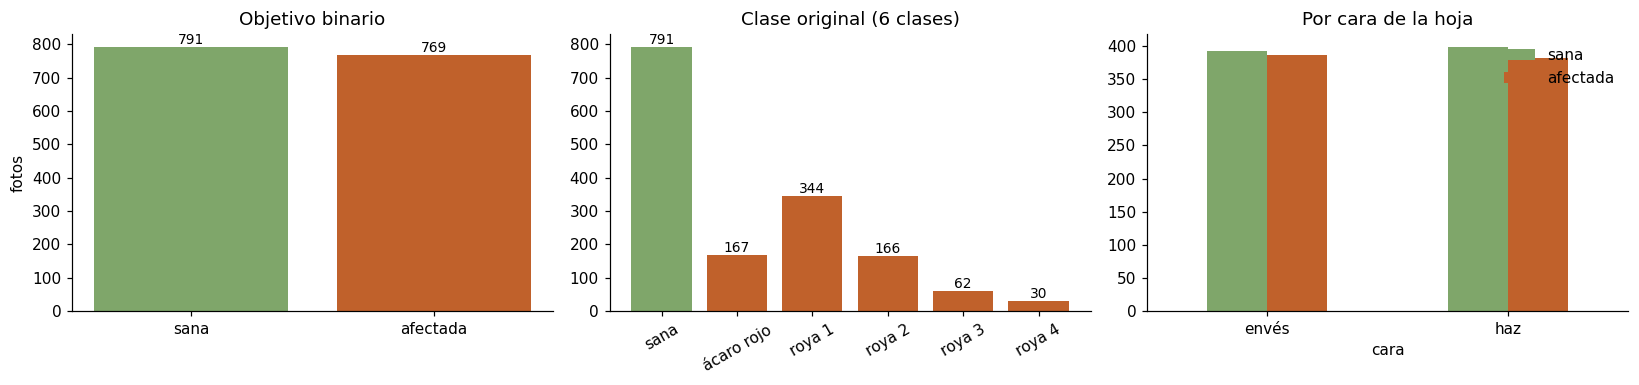

In [ ]:
NOMBRE = {"healthy": "sana", "red_spider_mite": "ácaro rojo", "rust_level_1": "roya 1",
          "rust_level_2": "roya 2", "rust_level_3": "roya 3", "rust_level_4": "roya 4"}
ORDEN = list(NOMBRE.values())
datos["clase"] = datos["clase_multi"].map(NOMBRE)
datos["afectada"] = (datos["clase_multi"] != "healthy").astype(int)

binaria = datos["afectada"].map({0: "sana", 1: "afectada"}).value_counts()
multi = datos["clase"].value_counts().reindex(ORDEN)
print("Binaria:", binaria.to_dict(), "→", (binaria / n_fotos * 100).round(1).to_dict(), "%")
print("Multiclase:", multi.to_dict())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].bar(binaria.index, binaria.values, color=["#7fa66a", "#c0612b"])
axes[0].set_title("Objetivo binario"); axes[0].set_ylabel("fotos")
axes[1].bar(multi.index, multi.values, color=["#7fa66a"] + ["#c0612b"] * 5)
axes[1].set_title("Clase original (6 clases)"); axes[1].tick_params(axis="x", rotation=30)
pd.crosstab(datos["cara"], datos["afectada"]).plot.bar(ax=axes[2], color=["#7fa66a", "#c0612b"], rot=0)
axes[2].set_title("Por cara de la hoja"); axes[2].legend(["sana", "afectada"], frameon=False)
for ax, d in zip(axes, [binaria, multi]):
    for i, v in enumerate(d.values):
        ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "eda_clases.png", bbox_inches="tight"); plt.show()

### 2.4 ¿Qué dicen los metadatos de cada foto (EXIF)?
Cada JPEG guarda la fecha de la toma, el celular y la resolución. La fecha es la que permite unir la foto con el clima en la Fase 2.

In [ ]:
def leer_exif(nombre):
    im = Image.open(RAW / "Photos" / nombre)
    exif = im.getexif()
    fecha = exif.get_ifd(0x8769).get(36867) or exif.get(306)     # DateTimeOriginal
    return {"archivo": nombre,
            "fecha": pd.to_datetime(fecha, format="%Y:%m:%d %H:%M:%S").normalize() if fecha else pd.NaT,
            "dispositivo": f"{exif.get(271, '')} {exif.get(272, '')}".strip(),
            "ancho": im.width, "alto": im.height, "tiene_gps": bool(exif.get_ifd(0x8825))}

datos = datos.merge(pd.DataFrame([leer_exif(f) for f in datos["archivo"]]), on="archivo")
datos["fecha_txt"] = datos["fecha"].dt.strftime("%Y-%m-%d")
print("Fotos sin fecha:", datos["fecha"].isna().sum(), "| con GPS:", datos["tiene_gps"].sum())
print("Resoluciones:", datos.groupby(["ancho", "alto"]).size().to_dict())
pd.crosstab(datos["fecha_txt"], datos["dispositivo"], margins=True, margins_name="total")

Fotos sin fecha: 0 | con GPS: 0
Resoluciones: {(1280, 720): 479, (2048, 1152): 768, (4128, 2322): 313}


dispositivo,samsung SM-G610M,samsung SM-J200M,samsung SM-J320H,samsung SM-J700M,total
fecha_txt,,,,,
2019-04-09,0,92,0,0,92
2019-04-10,0,230,0,192,422
2019-04-11,313,157,0,296,766
2019-05-01,0,132,0,0,132
2019-05-02,0,0,148,0,148
total,313,611,148,488,1560


**Lectura.**
- Todas las fotos tienen fecha: **5 días** entre abril y mayo de 2019.
- Las fotos se tomaron con **4 celulares Samsung** y vienen en **3 resoluciones**. Ninguna tiene GPS.
- Cada celular se usó en días concretos, así que **fecha y dispositivo van juntos**.

### 2.5 Calidad de los datos crudos (huella de crudeza)
Se revisa:
- Cuántas celdas vacías trae la exportación.
- Si hay fotos repetidas byte a byte y si las copias tienen la misma etiqueta.
- Si la etiqueta de la hoja (`state`) coincide con la clase.

In [ ]:
datos = datos.merge(manifiesto.loc[manifiesto["carpeta"] == "Photos", ["archivo", "sha256"]], on="archivo")
repetidas = datos.groupby("sha256")["archivo"].apply(list)
repetidas = repetidas[repetidas.str.len() > 1]
clase_de = datos.set_index("archivo")["clase"]

tabla_dup = pd.DataFrame({"archivos": [" = ".join(g) for g in repetidas],
                          "clases": [" / ".join(clase_de[g]) for g in repetidas]})
tabla_dup["misma_clase"] = [len(set(clase_de[g])) == 1 for g in repetidas]
tabla_dup["misma_binaria"] = [len({c == "sana" for c in clase_de[g]}) == 1 for g in repetidas]
tabla_dup.to_csv(RES / "duplicados_exactos.csv", index=False)

huella = {
    "anotaciones_csv_filas_x_columnas_crudo": f"{forma_csv_crudo[0]} × {forma_csv_crudo[1]}",
    "pct_faltantes_csv_global": round(float(csv_crudo.isna().mean().mean() * 100), 1),
    "columnas_csv_100pct_vacias": csv_crudo.columns[csv_crudo.isna().all()].tolist(),
    "imagenes": n_fotos, "plantas": n_plantas, "cultivos": n_cultivos, "hojas_inferidas": n_fotos // 2,
    "balance_afectada": datos["afectada"].value_counts().sort_index().to_dict(),
    "clases_multiclase": multi.to_dict(),
    "resoluciones": {f"{a}x{b}": int(n) for (a, b), n in datos.groupby(["ancho", "alto"]).size().items()},
    "dispositivos": datos["dispositivo"].value_counts().to_dict(),
    "fechas_captura": datos["fecha_txt"].value_counts().sort_index().to_dict(),
    "imagenes_con_gps": int(datos["tiene_gps"].sum()),
    "duplicados_exactos_grupos": len(repetidas),
    "duplicados_exactos_imagenes": int(repetidas.str.len().sum()),
    "duplicados_misma_clase_multi": int(tabla_dup["misma_clase"].sum()),
    "duplicados_misma_clase_binaria": int(tabla_dup["misma_binaria"].sum()),
    "nombres_anomalos": datos.loc[~datos["foto"].isin(["1", "2"]), "archivo"].tolist(),
    "inconsistencias_estado_vs_clase": int(((datos["estado"] == "unhealthy") != (datos["afectada"] == 1)).sum()),
}
for k, v in huella.items():
    print(f"{k:>40}: {v}")
tabla_dup.head(8)

  anotaciones_csv_filas_x_columnas_crudo: 1560 × 18
                pct_faltantes_csv_global: 23.5
              columnas_csv_100pct_vacias: ['Benchmark Agreement', 'Benchmark ID', 'Benchmark Reference ID']
                                imagenes: 1560
                                 plantas: 390
                                cultivos: 12
                         hojas_inferidas: 780
                        balance_afectada: {0: 791, 1: 769}
                       clases_multiclase: {'sana': 791, 'ácaro rojo': 167, 'roya 1': 344, 'roya 2': 166, 'roya 3': 62, 'roya 4': 30}
                            resoluciones: {'1280x720': 479, '2048x1152': 768, '4128x2322': 313}
                            dispositivos: {'samsung SM-J200M': 611, 'samsung SM-J700M': 488, 'samsung SM-G610M': 313, 'samsung SM-J320H': 148}
                          fechas_captura: {'2019-04-09': 92, '2019-04-10': 422, '2019-04-11': 766, '2019-05-01': 132, '2019-05-02': 148}
                        imagenes_con_gps:

,archivos,clases,misma_clase,misma_binaria
0,C10P26H1.jpg = C12P31H1.jpg,sana / sana,True,True
1,C11P11HE.jpg = C12P19H1.jpg,roya 4 / roya 3,False,True
2,C10P38E1.jpg = C11P25E1.jpg,sana / sana,True,True
3,C1P35H1.jpg = C1P38H1.jpg,sana / sana,True,True
4,C11P15H2.jpg = C12P25H2.jpg,ácaro rojo / roya 1,False,True
5,C11P10E2.jpg = C12P18E2.jpg,roya 2 / roya 2,True,True
6,C11P12E2.jpg = C12P21E2.jpg,roya 2 / roya 1,False,True
7,C10P30H1.jpg = C12P40H1.jpg,sana / sana,True,True


**Lectura y decisiones.**
- La exportación de Labelbox trae un 23,5 % de celdas vacías, concentradas en columnas administrativas que no se usan.
- Hay **67 grupos de fotos idénticas byte a byte** (134 fotos), siempre entre **plantas distintas**. En 27 de esos grupos las copias tienen una clase multiclase distinta (p. ej. "roya 4 / roya 3"), y en 1 difiere la binaria.
  - Es ruido de etiqueta de la fuente.
  - **No se eliminan ni se corrigen a mano.** En el paso 5 se agrupan para que una copia no quede en entrenamiento y la otra en prueba.
- En 8 fotos el `state` del polígono no coincide con la clase. Se usa la clase (`classification`), que coincide con la tabla XLSX.

### 2.6 Resumen: variables iniciales

| Variable | De dónde sale | Para qué se usa |
|---|---|---|
| `archivo` | Nombre del JPEG | Identificador |
| `cultivo`, `planta` | Nombre del archivo | **Agrupar** en la partición (no son predictores) |
| `cara`, `foto` | Nombre del archivo | Análisis por subgrupo |
| `clase_multi` → `clase` | Anotación (`classification`) | Severidad para el análisis por subgrupo |
| `afectada` (0/1) | Derivada de `clase_multi` | **Objetivo** |
| `poligono` | Anotación (`Leaf.geometry`) | Recortar la hoja de la foto |
| `fecha` | EXIF `DateTimeOriginal` | **Clave** para unir con el clima (Fase 2) |
| `dispositivo`, `ancho`, `alto` | EXIF | Control de calidad (no son predictores: describen la cámara, no la hoja) |
| `sha256` | Calculada sobre el archivo | Detectar duplicados |

Ninguna de estas variables describe **cómo se ve la hoja**. El modelo necesita esa información en forma de números, y es lo que se construye en el paso 3.

## 3 · Variables que agregamos: describir la hoja con números
### ¿Por qué?
Un MLP recibe una fila de números, no una foto. En esta Fase 1 la foto se **resume** en un vector de rasgos con significado biológico. En la Fase 2 la CNN aprenderá sus propios rasgos directamente de los píxeles.

### ¿Cómo?
1. Con el polígono anotado se recorta **solo la hoja**, sin el fondo.
2. Se redimensiona a 256 px, porque las fotos vienen en 3 resoluciones.
3. Se calculan 28 rasgos sobre los píxeles de la hoja:

| Familia | Rasgos | Por qué ayudan a distinguir una hoja afectada |
|---|---|---|
| Color medio y su variación | Media y desviación de R, G, B, de H, S, V y de a*, b* (CIELAB) | Una hoja sana es verde y uniforme; las lesiones cambian el tono y aumentan la variación |
| Proporción de lesión | `pct_naranja`, `pct_amarillo`, `pct_oscuro`, `pct_verde`, `pct_lesion = 1 − pct_verde` | Las pústulas de roya son anaranjadas, la clorosis es amarilla y la necrosis es oscura |
| Índices de vegetación | ExG, VARI y R/G | Miden cuánto verdor se pierde |
| Textura (GLCM) | Contraste, disimilitud, homogeneidad, energía y correlación | La roya y el ácaro dejan un patrón punteado; la hoja sana es lisa |
| Forma | `fraccion_hoja` | Qué tanto de la caja recortada ocupa la hoja |

También se calcula el **pHash**, una huella visual que sirve para encontrar fotos *casi* idénticas.

El paso tarda unos 2 minutos. Los rasgos quedan en caché para no recalcularlos.

In [ ]:
def rasgos_hoja(nombre, poligono):
    im = Image.open(RAW / "Photos" / nombre)
    W, H = im.size
    im.draft("RGB", (W // 2, H // 2))                 # decodifica a la mitad de tamaño (más rápido)
    im = im.convert("RGB")
    sx, sy = im.width / W, im.height / H

    # 1. Recortar la hoja con su polígono
    mascara = Image.new("L", im.size, 0)
    ImageDraw.Draw(mascara).polygon([(q["x"] * sx, q["y"] * sy) for q in poligono], fill=1)
    caja = mascara.getbbox()
    hoja, mascara = im.crop(caja), mascara.crop(caja)

    # 2. Redimensionar a 256 px por el lado mayor
    f = 256 / max(hoja.size)
    tam = (max(1, round(hoja.width * f)), max(1, round(hoja.height * f)))
    rgb = np.asarray(hoja.resize(tam, Image.BILINEAR), dtype=np.float32) / 255
    m = np.asarray(mascara.resize(tam, Image.NEAREST)).astype(bool)

    # 3. Rasgos sobre los píxeles de la hoja
    R, G, B = rgb[m, 0], rgb[m, 1], rgb[m, 2]
    Hh, S, V = rgb2hsv(rgb)[m].T
    lab = rgb2lab(rgb)[m]
    r = {"archivo": nombre, "phash": str(imagehash.phash(im))}
    for nombre_canal, canal in zip("RGBHSV", [R, G, B, Hh, S, V]):
        r[f"media_{nombre_canal}"], r[f"std_{nombre_canal}"] = float(canal.mean()), float(canal.std())
    r["media_a_lab"], r["media_b_lab"] = float(lab[:, 1].mean()), float(lab[:, 2].mean())

    verde = (Hh >= 0.17) & (Hh < 0.50) & (S > 0.15) & (V > 0.15)
    naranja = ((Hh < 0.11) | (Hh >= 0.95)) & (S > 0.35) & (V > 0.25)
    amarillo = (Hh >= 0.11) & (Hh < 0.17) & (S > 0.30) & (V > 0.30)
    r["pct_verde"], r["pct_naranja"] = float(verde.mean()), float(naranja.mean())
    r["pct_amarillo"], r["pct_oscuro"] = float(amarillo.mean()), float((V < 0.15).mean())
    r["pct_lesion"] = 1.0 - r["pct_verde"]

    suma = R + G + B + 1e-6
    r["exg"] = float((2 * G / suma - R / suma - B / suma).mean())
    den = G + R - B
    vari = np.where(np.abs(den) > 1e-3, (G - R) / np.where(np.abs(den) > 1e-3, den, 1), 0)
    r["vari"] = float(np.clip(vari, -1, 1).mean())
    r["razon_rg"] = float((R / (G + 1e-3)).mean())

    gris = 0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]
    q = np.where(m, 1 + np.minimum((gris * 31).astype(int), 30), 0).astype(np.uint8)   # 0 = fondo
    P = graycomatrix(q, [1, 2], [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=32, symmetric=True)[1:, 1:].astype(float)
    P /= P.sum(axis=(0, 1), keepdims=True)
    for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]:
        r[f"glcm_{prop}"] = float(np.nanmean(graycoprops(P, prop)))
    r["fraccion_hoja"] = float(m.mean())
    return r

cache = PROC / "_cache_rasgos.csv"
if cache.exists():
    rasgos = pd.read_csv(cache)
else:
    rasgos = pd.DataFrame([rasgos_hoja(a, p) for a, p in zip(datos["archivo"], datos["poligono"])])
    rasgos.to_csv(cache, index=False)

df = datos.drop(columns=["poligono", "estado"]).merge(rasgos, on="archivo")
RASGOS_TABLA = [c for c in rasgos.columns if c not in ("archivo", "phash")]
df.to_csv(PROC / "rocole_tabular_features_fase1.csv", index=False)
print("Tabla final:", df.shape, "→ data/processed/rocole_tabular_features_fase1.csv")
df[["archivo", "clase", "afectada"] + RASGOS_TABLA[:6] + ["pct_naranja", "pct_lesion"]].head()

Tabla final: (1560, 44) → data/processed/rocole_tabular_features_fase1.csv


,archivo,clase,afectada,media_R,std_R,media_G,std_G,media_B,std_B,pct_naranja,pct_lesion
0,C10P10E1.jpg,sana,0,0.529663,0.065230,0.635246,0.082231,0.497866,0.077789,0.000000,0.088750
1,C10P10E2.jpg,roya 1,1,0.589860,0.100147,0.665397,0.105673,0.537393,0.105643,0.002045,0.255054
2,C10P10H1.jpg,sana,0,0.416234,0.121959,0.687456,0.080131,0.344295,0.132904,0.000000,0.007862
3,C10P10H2.jpg,roya 2,1,0.401531,0.174530,0.603484,0.159429,0.352831,0.196444,0.000447,0.026847
4,C10P11E1.jpg,sana,0,0.575017,0.121684,0.667459,0.110537,0.556142,0.134035,0.000000,0.368236


### ¿Qué variables entran al modelo?

| Grupo | Entra al MLP | Motivo |
|---|---|---|
| 27 rasgos de la hoja | **Sí** | Describen la hoja |
| `pct_verde` | No | Es exactamente `1 − pct_lesion`: repetirlo no aporta información |
| `planta`, `cultivo`, `sha256`, `phash` | No | Se usan para agrupar la partición |
| `fecha` | No (en la Fase 1) | Es la clave del clima para la Fase 2 |
| `dispositivo`, resolución | No | Describen la cámara; el modelo podría aprender "qué celular tomó la foto" |
| `cara`, `clase` | No | Se usan para analizar errores por subgrupo |

In [ ]:
RASGOS = [c for c in RASGOS_TABLA if c != "pct_verde"]
print(len(RASGOS), "rasgos de entrada:", RASGOS)

27 rasgos de entrada: ['media_R', 'std_R', 'media_G', 'std_G', 'media_B', 'std_B', 'media_H', 'std_H', 'media_S', 'std_S', 'media_V', 'std_V', 'media_a_lab', 'media_b_lab', 'pct_naranja', 'pct_amarillo', 'pct_oscuro', 'pct_lesion', 'exg', 'vari', 'razon_rg', 'glcm_contrast', 'glcm_dissimilarity', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation', 'fraccion_hoja']


## 4 · Exploración de las variables agregadas
- **Entrada:** `rocole_tabular_features_fase1.csv`.
- **Revisión:**
  1. Faltantes, ceros y atípicos (regla IQR).
  2. Distribución por clase binaria y por severidad.
  3. Correlación y multicolinealidad.
  4. Posibles variables de confusión.
- **Regla:** los atípicos biológicos reales, como las hojas con roya de grado 4, **no se eliminan**.

### 4.1 Faltantes, ceros y atípicos

In [ ]:
def revisar(col):
    x = df[col]
    q1, q3 = x.quantile([0.25, 0.75])
    atipico = (x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))
    severa = df["clase"].isin(["roya 3", "roya 4"])
    return {"rasgo": col, "nan": int(x.isna().sum()), "ceros": int((x == 0).sum()),
            "pct_ceros": round(100 * (x == 0).mean(), 1),
            "atipicos_iqr": int(atipico.sum()), "pct_atipicos": round(100 * atipico.mean(), 1),
            "pct_atip_sanas": round(100 * atipico[df["afectada"] == 0].mean(), 1),
            "pct_atip_roya3_4": round(100 * atipico[severa].mean(), 1)}

auditoria_iqr = pd.DataFrame([revisar(c) for c in RASGOS_TABLA]).set_index("rasgo")
auditoria_iqr.to_csv(RES / "eda_auditoria_iqr.csv")
huella["nan_en_rasgos"] = int(auditoria_iqr["nan"].sum())
print("NaN en rasgos:", huella["nan_en_rasgos"])
for c in auditoria_iqr.index[auditoria_iqr["ceros"] > 0]:
    print(f"Ceros en {c}: {df.loc[df[c] == 0, 'clase'].value_counts().to_dict()}")
auditoria_iqr.sort_values("pct_atipicos", ascending=False).head(10)

NaN en rasgos: 0
Ceros en pct_naranja: {'sana': 518, 'roya 1': 62, 'ácaro rojo': 6, 'roya 2': 4}
Ceros en pct_amarillo: {'sana': 207, 'roya 1': 7, 'ácaro rojo': 2}
Ceros en pct_oscuro: {'sana': 453, 'roya 1': 190, 'roya 2': 79, 'ácaro rojo': 72, 'roya 3': 26, 'roya 4': 13}
Ceros en pct_lesion: {'sana': 3}


,nan,ceros,pct_ceros,atipicos_iqr,pct_atipicos,pct_atip_sanas,pct_atip_roya3_4
rasgo,,,,,,,
pct_oscuro,0,833,53.4,257,16.5,14.2,23.9
pct_naranja,0,590,37.8,208,13.3,0.9,45.7
pct_amarillo,0,216,13.8,191,12.2,1.6,54.3
pct_verde,0,0,0.0,125,8.0,3.8,32.6
pct_lesion,0,3,0.2,125,8.0,3.8,32.6
std_H,0,0,0.0,88,5.6,1.8,32.6
fraccion_hoja,0,0,0.0,75,4.8,7.5,1.1
glcm_contrast,0,0,0.0,57,3.7,4.7,3.3
glcm_energy,0,0,0.0,35,2.2,2.4,0.0


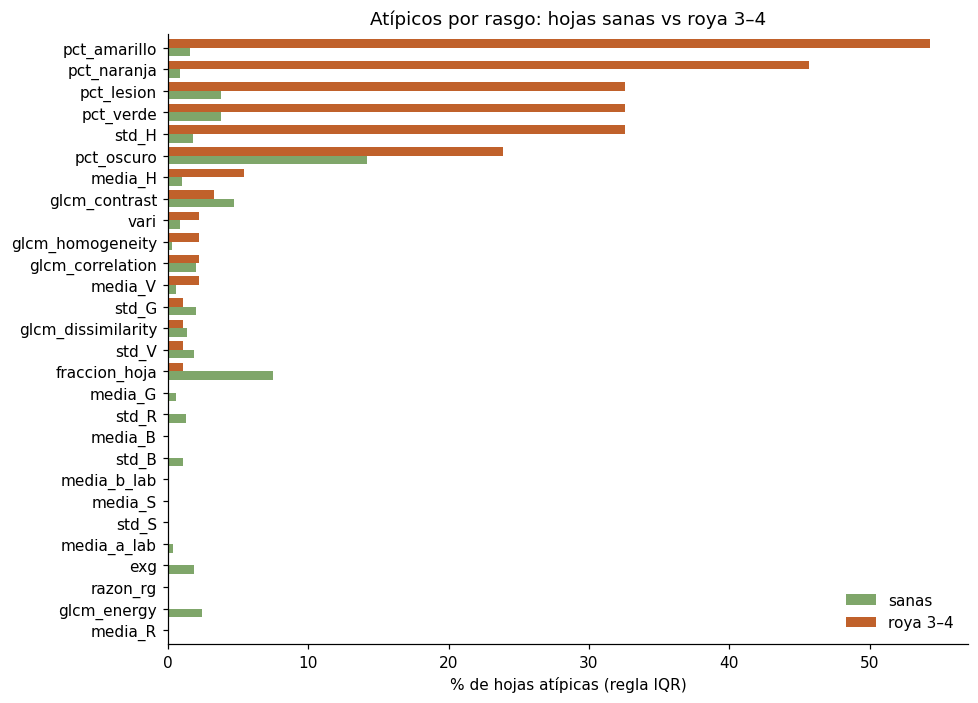

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6.5))
auditoria_iqr[["pct_atip_sanas", "pct_atip_roya3_4"]].sort_values("pct_atip_roya3_4").plot.barh(
    ax=ax, width=0.8, color=["#7fa66a", "#c0612b"])
ax.set_xlabel("% de hojas atípicas (regla IQR)"); ax.set_ylabel("")
ax.set_title("Atípicos por rasgo: hojas sanas vs roya 3–4")
ax.legend(["sanas", "roya 3–4"], frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "eda_atipicos_iqr.png", bbox_inches="tight"); plt.show()

**Lectura.**
- No hay NaN.
- Los ceros de `pct_naranja` (590) y `pct_amarillo` (216) son casi todos de hojas sanas: no tienen lesión. Son **ceros biológicos**.
- Los atípicos son la señal de la enfermedad. Por eso **se conservan**:

| Rasgo | % atípico en roya 3–4 | % atípico en sanas |
|---|---|---|
| `pct_amarillo` | 54,3 | 1,6 |
| `pct_naranja` | 45,7 | 0,9 |

### 4.2 Distribución por clase binaria y por severidad

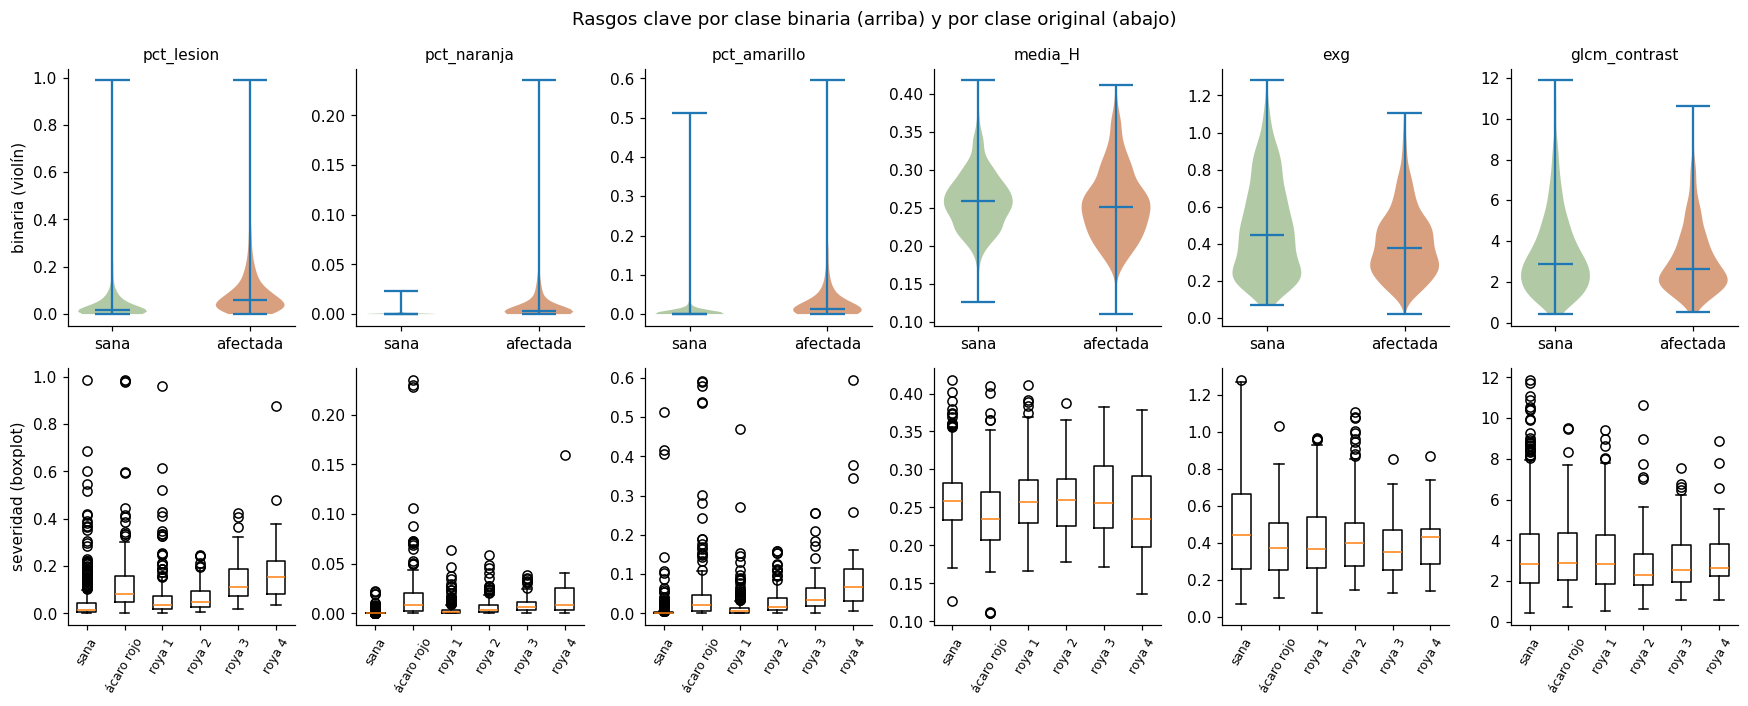

Rasgos que mejor separan por sí solos (AUC univariado):
pct_amarillo     0.876
pct_naranja      0.869
pct_verde        0.752
pct_lesion       0.752
std_H            0.703
fraccion_hoja    0.619
dtype: float64


In [ ]:
CLAVE = ["pct_lesion", "pct_naranja", "pct_amarillo", "media_H", "exg", "glcm_contrast"]
fig, axes = plt.subplots(2, len(CLAVE), figsize=(16, 6.5))
for j, c in enumerate(CLAVE):
    vp = axes[0, j].violinplot([df.loc[df["afectada"] == k, c] for k in (0, 1)], showmedians=True)
    for cuerpo, color in zip(vp["bodies"], ["#7fa66a", "#c0612b"]):
        cuerpo.set_facecolor(color); cuerpo.set_alpha(0.6)
    axes[0, j].set_xticks([1, 2], ["sana", "afectada"]); axes[0, j].set_title(c, fontsize=10)
    axes[1, j].boxplot([df.loc[df["clase"] == k, c] for k in ORDEN], tick_labels=ORDEN)
    axes[1, j].tick_params(axis="x", rotation=60, labelsize=8)
axes[0, 0].set_ylabel("binaria (violín)"); axes[1, 0].set_ylabel("severidad (boxplot)")
fig.suptitle("Rasgos clave por clase binaria (arriba) y por clase original (abajo)")
fig.tight_layout(); fig.savefig(FIG / "eda_distribuciones.png", bbox_inches="tight"); plt.show()

auc_uni = pd.Series({c: roc_auc_score(df["afectada"], df[c]) for c in RASGOS_TABLA})
auc_uni = auc_uni.where(auc_uni >= 0.5, 1 - auc_uni).sort_values(ascending=False)
print("Rasgos que mejor separan por sí solos (AUC univariado):"); print(auc_uni.head(6).round(3))

### 4.3 Correlación y multicolinealidad

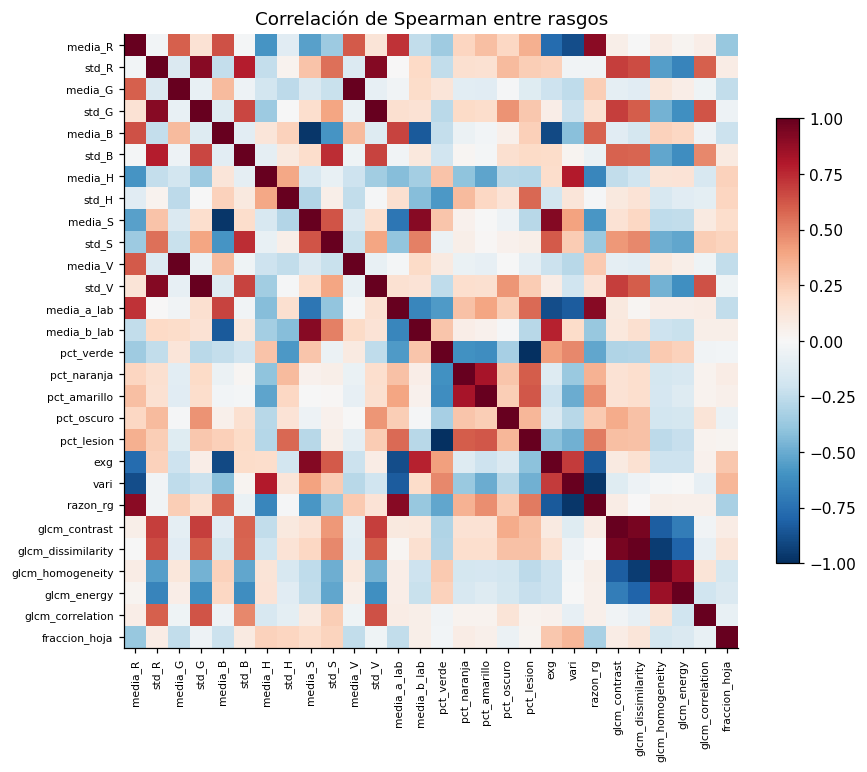

Pares con |ρ| > 0,9: 14
   pct_verde ~ pct_lesion: -1.000
   media_G ~ media_V: +0.998
   std_G ~ std_V: +0.998
   vari ~ razon_rg: -0.972
   media_B ~ media_S: -0.970
   glcm_dissimilarity ~ glcm_homogeneity: -0.953
Correlación de Pearson media en valor absoluto: 0.266
Rasgos del modelo con VIF > 10: 19 de 27


In [ ]:
corr_s = df[RASGOS_TABLA].corr("spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im_ = ax.imshow(corr_s, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(RASGOS_TABLA)), RASGOS_TABLA, rotation=90, fontsize=7)
ax.set_yticks(range(len(RASGOS_TABLA)), RASGOS_TABLA, fontsize=7)
ax.set_title("Correlación de Spearman entre rasgos"); fig.colorbar(im_, shrink=0.7)
fig.savefig(FIG / "eda_correlaciones.png", bbox_inches="tight"); plt.show()

pares = [(a, b, corr_s.loc[a, b]) for i, a in enumerate(RASGOS_TABLA) for b in RASGOS_TABLA[i + 1:] if abs(corr_s.loc[a, b]) > 0.9]
print(f"Pares con |ρ| > 0,9: {len(pares)}")
for a, b, r_ in sorted(pares, key=lambda t: -abs(t[2]))[:6]:
    print(f"   {a} ~ {b}: {r_:+.3f}")
corr_p = df[RASGOS_TABLA].corr("pearson")
print("Correlación de Pearson media en valor absoluto:", round(float(corr_p.abs().values[np.triu_indices(len(RASGOS_TABLA), 1)].mean()), 3))

Z = (df[RASGOS] - df[RASGOS].mean()) / df[RASGOS].std()
vif = pd.Series([variance_inflation_factor(Z.values, i) for i in range(len(RASGOS))], index=RASGOS)
print(f"Rasgos del modelo con VIF > 10: {(vif > 10).sum()} de {len(RASGOS)}")

**Lectura.**
- Muchos rasgos están muy correlacionados. Por ejemplo, `media_G` y `media_V` casi son el mismo número, porque el brillo de una hoja verde depende del canal verde.
- **Se conservan todos.** Un MLP no invierte una matriz de diseño, así que la colinealidad no lo rompe. Además, si se eligieran variables mirando todos los datos se filtraría información de la prueba.
- En el paso 12 se mide cuáles rasgos usa realmente el modelo.

### 4.4 ¿La clase depende de la cámara, del día o de la cara de la hoja?
Se mide con la V de Cramér: 0 significa que no hay asociación y 1 que la asociación es total.

V de Cramér con 'afectada': {'dispositivo': 0.028, 'fecha_txt': 0.024, 'cara': 0.005, 'cultivo': 0.045}


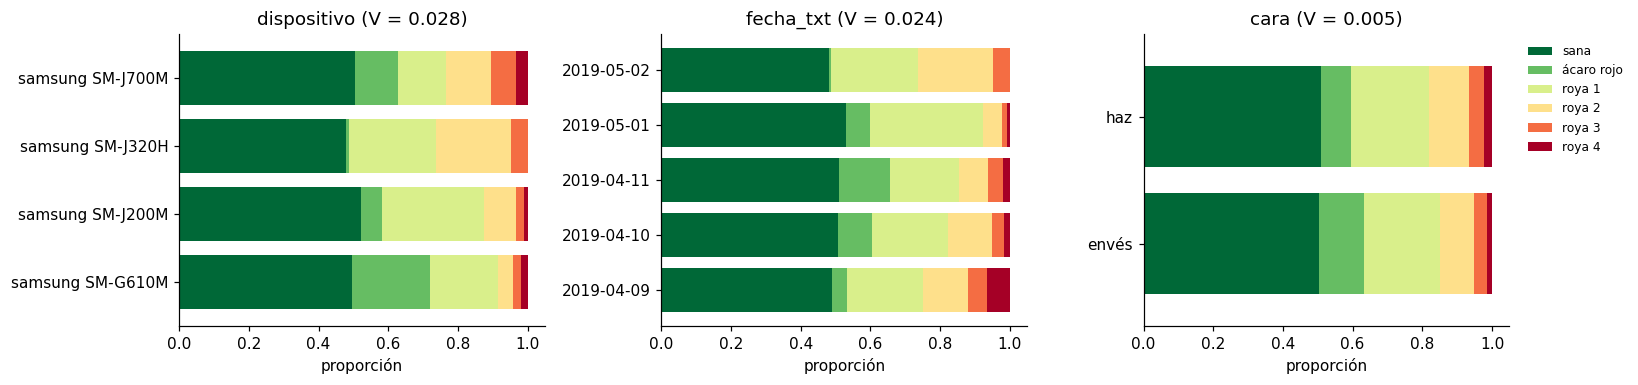

In [ ]:
def v_cramer(a, b):
    t = pd.crosstab(a, b)
    return float(np.sqrt(stats.chi2_contingency(t)[0] / (t.values.sum() * (min(t.shape) - 1))))
confusores = {v: round(v_cramer(df[v], df["afectada"]), 3) for v in ["dispositivo", "fecha_txt", "cara", "cultivo"]}
print("V de Cramér con 'afectada':", confusores)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, v in zip(axes, ["dispositivo", "fecha_txt", "cara"]):
    pd.crosstab(df[v], df["clase"], normalize="index")[ORDEN].plot.barh(stacked=True, ax=ax, legend=False, colormap="RdYlGn_r", width=0.8)
    ax.set_title(f"{v} (V = {confusores[v]})"); ax.set_xlabel("proporción"); ax.set_ylabel("")
axes[-1].legend(ORDEN, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "eda_confusores.png", bbox_inches="tight"); plt.show()

**Lectura.** La proporción de hojas afectadas es prácticamente la misma en cada celular, día y cara (todas las V < 0,05). La clase no está confundida con la cámara.

Aun así, la cámara puede cambiar el **color** de la foto. Por eso en el paso 11 se revisan los errores por celular.

In [ ]:
decisiones_eda = pd.DataFrame([
    ("Balance de 769 afectadas frente a 791 sanas (por diseño del muestreo)", "Partición estratificada; la línea base es la clase mayoritaria"),
    ("4 fotos por planta, probablemente 2 hojas × 2 caras", "Partición agrupada por planta"),
    ("67 grupos de duplicados byte a byte entre plantas; 27 con clase distinta", "Se conservan y se agrupan; no se corrigen a mano"),
    ("Sin NaN; ceros biológicos en los rasgos de lesión", "Sin imputación"),
    ("Atípicos concentrados en roya 3–4", "Se conservan (son señal)"),
    ("Rasgos muy colineales; pct_verde = 1 − pct_lesion", "Se conservan todos, salvo pct_verde"),
    ("Clase no asociada al celular ni al día; celular y día confundidos entre sí", "Se excluye el dispositivo de X; errores por celular en el paso 11"),
    ("Fecha EXIF en todas las fotos (5 días)", "Clave temporal (CIIDEA, fecha) para la Fase 2"),
], columns=["Hallazgo", "Decisión"])
decisiones_eda.to_csv(RES / "eda_decisiones.csv", index=False)
RESULTADOS["huella_crudeza"] = huella
RESULTADOS["eda_auditoria"] = {"nan_total": huella["nan_en_rasgos"], "pct_atipicos_medio": float(auditoria_iqr["pct_atipicos"].mean().round(1))}
RESULTADOS["eda_auc_univariado_top5"] = auc_uni.head(5).round(3).to_dict()
RESULTADOS["eda_multicolinealidad"] = {"pares_spearman_mayor_0_9": len(pares), "rasgos_vif_mayor_10": int((vif > 10).sum())}
RESULTADOS["eda_v_cramer"] = confusores
pd.set_option("display.max_colwidth", 120); decisiones_eda

,Hallazgo,Decisión
0,Balance de 769 afectadas frente a 791 sanas (por diseño del muestreo),Partición estratificada; la línea base es la clase mayoritaria
1,"4 fotos por planta, probablemente 2 hojas × 2 caras",Partición agrupada por planta
2,67 grupos de duplicados byte a byte entre plantas; 27 con clase distinta,Se conservan y se agrupan; no se corrigen a mano
3,Sin NaN; ceros biológicos en los rasgos de lesión,Sin imputación
4,Atípicos concentrados en roya 3–4,Se conservan (son señal)
5,Rasgos muy colineales; pct_verde = 1 − pct_lesion,"Se conservan todos, salvo pct_verde"
6,Clase no asociada al celular ni al día; celular y día confundidos entre sí,Se excluye el dispositivo de X; errores por celular en el paso 11
7,Fecha EXIF en todas las fotos (5 días),"Clave temporal (CIIDEA, fecha) para la Fase 2"


## 5 · Unir con el clima y armar los grupos
### 5.1 Prueba de acoplamiento con NASA POWER (para la Fase 2)
- La clave es `(CIIDEA, fecha de la foto)`.
- Para cada fecha se toma el clima diario de los **60 días anteriores**, sin incluir el día de la foto.
- En la Fase 1 el clima **no entra al modelo**: solo se demuestra que la unión funciona con 10 filas reales.

In [ ]:
fechas = sorted(df["fecha"].unique())
ruta_clima = ROOT / "data" / "external" / "nasa_power_ciidea_diario.csv"
ruta_clima.parent.mkdir(parents=True, exist_ok=True)
try:
    r = requests.get("https://power.larc.nasa.gov/api/temporal/daily/point", timeout=120, params={
        "parameters": "T2M,RH2M,PRECTOTCORR,WS2M", "community": "AG", "latitude": LAT, "longitude": LON, "format": "JSON",
        "start": (fechas[0] - pd.Timedelta(days=VENTANA_DIAS)).strftime("%Y%m%d"),
        "end": (fechas[-1] - pd.Timedelta(days=1)).strftime("%Y%m%d")})
    clima = pd.DataFrame(r.json()["properties"]["parameter"])
    clima.index = pd.to_datetime(clima.index, format="%Y%m%d")
    clima.to_csv(ruta_clima, index_label="fecha")
except Exception as e:
    print("NASA POWER no disponible; se usa la copia local:", e)
    clima = pd.read_csv(ruta_clima, index_col="fecha", parse_dates=True)

ventanas = []
for d in fechas:
    w = clima.loc[d - pd.Timedelta(days=VENTANA_DIAS): d - pd.Timedelta(days=1)]
    ventanas.append({"fecha": d, "dias_ventana": len(w), "T2M_media_60d": w["T2M"].mean(), "RH2M_media_60d": w["RH2M"].mean(),
                     "PRECTOTCORR_suma_60d": w["PRECTOTCORR"].sum(), "WS2M_media_60d": w["WS2M"].mean()})
ventanas = pd.DataFrame(ventanas)
print(ventanas.round(2).to_string(index=False))

muestra = df.groupby("fecha").sample(2, random_state=SEMILLA)[["archivo", "fecha", "clase", "pct_lesion"]].merge(ventanas, on="fecha")
muestra.insert(0, "sitio", "CIIDEA (-0.834206, -80.177159)")
muestra.to_csv(RES / "acoplamiento_10_filas.csv", index=False)
muestra.round(3)

     fecha  dias_ventana  T2M_media_60d  RH2M_media_60d  PRECTOTCORR_suma_60d  WS2M_media_60d
2019-04-09            60          25.80           85.82                643.78            1.57
2019-04-10            60          25.79           85.88                641.95            1.57
2019-04-11            60          25.79           85.80                627.27            1.56
2019-05-01            60          25.67           86.15                518.38            1.53
2019-05-02            60          25.66           86.21                517.76            1.54


,sitio,archivo,fecha,clase,pct_lesion,dias_ventana,T2M_media_60d,RH2M_media_60d,PRECTOTCORR_suma_60d,WS2M_media_60d
0,"CIIDEA (-0.834206, -80.177159)",C9P20H1.jpg,2019-04-09,roya 1,0.012,60,25.800,85.824,643.78,1.569
1,"CIIDEA (-0.834206, -80.177159)",C9P15E1.jpg,2019-04-09,roya 3,0.212,60,25.800,85.824,643.78,1.569
2,"CIIDEA (-0.834206, -80.177159)",C6P14E2.jpg,2019-04-10,sana,0.002,60,25.789,85.880,641.95,1.571
3,"CIIDEA (-0.834206, -80.177159)",C10P2E2.jpg,2019-04-10,sana,0.012,60,25.789,85.880,641.95,1.571
4,"CIIDEA (-0.834206, -80.177159)",C11P28H1.jpg,2019-04-11,sana,0.024,60,25.792,85.803,627.27,1.562
5,"CIIDEA (-0.834206, -80.177159)",C3P5E2.jpg,2019-04-11,ácaro rojo,0.177,60,25.792,85.803,627.27,1.562
6,"CIIDEA (-0.834206, -80.177159)",C5P13E1.jpg,2019-05-01,sana,0.042,60,25.666,86.153,518.38,1.529
7,"CIIDEA (-0.834206, -80.177159)",C5P28E1.jpg,2019-05-01,roya 1,0.329,60,25.666,86.153,518.38,1.529
8,"CIIDEA (-0.834206, -80.177159)",C1P14H1.jpg,2019-05-02,sana,0.024,60,25.659,86.210,517.76,1.537
9,"CIIDEA (-0.834206, -80.177159)",C1P35E1.jpg,2019-05-02,sana,0.040,60,25.659,86.210,517.76,1.537


**Lectura.**
- La unión funciona: 83 días de clima, sin faltantes.
- Pero las 5 ventanas son **casi iguales**: unos 25,7 °C, 86 % de humedad relativa y entre 518 y 644 mm de lluvia.
- **Implicación para la Fase 2:** el clima servirá como contexto de riesgo, pero no distinguirá entre hojas del mismo día. Es una limitación declarada.

### 5.2 Grupos: fotos que deben ir juntas en la partición
Si dos fotos son de la misma planta, o una es copia de la otra, deben quedar en el **mismo** subconjunto. Si no, el modelo "vería" la prueba durante el entrenamiento.

Se unen las plantas que comparten:
- una foto idéntica (SHA-256), o
- una foto casi idéntica (pHash con distancia ≤ 5).

In [ ]:
padre = {p: p for p in df["planta"].unique()}
def raiz(a):
    while padre[a] != a:
        padre[a] = padre[padre[a]]; a = padre[a]
    return a
def unir(a, b):
    ra, rb = raiz(a), raiz(b)
    if ra != rb:
        padre[max(ra, rb)] = min(ra, rb)

planta_de = df.set_index("archivo")["planta"]
for grupo in repetidas:                                  # duplicados exactos
    for a in grupo[1:]:
        unir(planta_de[grupo[0]], planta_de[a])

bits = np.array([np.unpackbits(np.frombuffer(bytes.fromhex(h), dtype=np.uint8)) for h in df["phash"]], dtype=np.int32)
distancia = bits @ (1 - bits).T + (1 - bits) @ bits.T  # distancia de Hamming entre pHash
casi = [(df["archivo"].iat[i], df["archivo"].iat[j]) for i, j in zip(*np.where(np.triu(distancia <= 5, k=1)))
        if df["sha256"].iat[i] != df["sha256"].iat[j]]
for a, b in casi:                                        # casi duplicados
    unir(planta_de[a], planta_de[b])

df["id_grupo"] = df["planta"].map(raiz)
tam = df.groupby("id_grupo").size()
RESULTADOS["grupos"] = {"plantas": n_plantas, "grupos": int(df["id_grupo"].nunique()),
                        "casi_duplicados_phash_no_exactos": len(casi), "tam_max_grupo": int(tam.max())}
print(RESULTADOS["grupos"]); print("Fotos por grupo:", tam.value_counts().sort_index().to_dict())

{'plantas': 390, 'grupos': 342, 'casi_duplicados_phash_no_exactos': 15, 'tam_max_grupo': 92}
Fotos por grupo: {4: 322, 8: 16, 16: 2, 20: 1, 92: 1}


## 6 · Partición entrenamiento / validación / prueba (70 / 15 / 15)
- `StratifiedGroupKFold` divide los grupos en 20 pliegues de proporción de clases parecida.
- 3 pliegues van a validación y 3 a prueba. Se eligen por tamaño para acercarse al 15 % cada uno, porque hay un grupo de 92 fotos; en esa elección no se usa la etiqueta.
- No se parte por fecha: solo hay 5 días y en esta fase el modelo usa la imagen, no el clima.

In [ ]:
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEMILLA)
pliegue = np.empty(len(df), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(df[RASGOS], df["afectada"], df["id_grupo"])):
    pliegue[idx] = k

n_pliegue, meta = np.bincount(pliegue, minlength=20), 0.15 * len(df)
mejor = None
for va in combinations(range(20), 3):
    error_va = abs(n_pliegue[list(va)].sum() - meta)
    if error_va > 0.02 * len(df):
        continue
    for te in combinations([k for k in range(20) if k not in va], 3):
        error = error_va + abs(n_pliegue[list(te)].sum() - meta)
        if mejor is None or error < mejor[0]:
            mejor = (error, va, te)
df["subconjunto"] = np.where(np.isin(pliegue, mejor[1]), "validacion", np.where(np.isin(pliegue, mejor[2]), "prueba", "entrenamiento"))

# Verificaciones: ningún grupo ni duplicado queda repartido entre dos subconjuntos
assert (df.groupby("id_grupo")["subconjunto"].nunique() == 1).all()
assert (df.groupby("sha256")["subconjunto"].nunique() == 1).all()
resumen_part = df.groupby("subconjunto").agg(imagenes=("archivo", "size"), grupos=("id_grupo", "nunique"),
                                             pct_afectada=("afectada", "mean")).reindex(["entrenamiento", "validacion", "prueba"])
resumen_part["pct_imagenes"] = resumen_part["imagenes"] / len(df)
RESULTADOS["particion"] = resumen_part.round(3).reset_index().to_dict(orient="records")
df[["archivo", "planta", "id_grupo", "subconjunto"]].to_csv(RES / "particion.csv", index=False)    # se conserva para la Fase 2
resumen_part.round(3)

,imagenes,grupos,pct_afectada,pct_imagenes
subconjunto,,,,
entrenamiento,1092,234,0.493,0.700
validacion,232,55,0.483,0.149
prueba,236,53,0.504,0.151


## 7 · Escalamiento
`StandardScaler` se ajusta **solo con entrenamiento** y se aplica a validación y prueba.

In [ ]:
es_tr, es_va, es_te = (df["subconjunto"] == s for s in ("entrenamiento", "validacion", "prueba"))
escalador = StandardScaler().fit(df.loc[es_tr, RASGOS])

def a_tensores(filas, esc=escalador):
    X = torch.tensor(esc.transform(df.loc[filas, RASGOS]), dtype=torch.float32)
    y = torch.tensor(df.loc[filas, "afectada"].values, dtype=torch.float32).reshape(-1, 1)   # (N, 1) float
    return X, y

X_tr, y_tr = a_tensores(es_tr)
X_va, y_va = a_tensores(es_va)
X_te, y_te = a_tensores(es_te)
y_va_np, y_te_np = y_va.numpy().ravel().astype(int), y_te.numpy().ravel().astype(int)
n_feat = X_tr.shape[1]
print("Entrenamiento", tuple(X_tr.shape), "| validación", tuple(X_va.shape), "| prueba", tuple(X_te.shape), "| y:", y_tr.dtype)

Entrenamiento (1092, 27) | validación (232, 27) | prueba (236, 27) | y: torch.float32


## 8 · El modelo: un MLP
- **Arquitectura:** `Linear → ReLU → Dropout`, repetido dos veces, y luego `Linear(k, 1)`, que devuelve un **logit**. No hay sigmoide dentro del modelo.
- **Ruta de la salida:** el logit va a `BCEWithLogitsLoss` durante el entrenamiento, y `torch.sigmoid` se aplica solo al evaluar. Así se evita el doble sigmoide.
- **¿Por qué ReLU?** Las señales se combinan. Un tono anaranjado indica roya solo si va con textura punteada y pérdida de verdor; un brillo rojizo sobre una hoja lisa no la indica.
  - Sin una función no lineal, apilar capas `Linear` equivale a una sola capa lineal: no podría representar esas combinaciones.
  - Con ReLU el MLP aproxima la frontera por tramos (Teorema de Aproximación Universal).

-**Estructura Modelo: 27 -> 16 -> 8 -> 1**\
    (0): Linear(in_features=27, out_features=16, bias=True)\
    (1): ReLU()\
    (2): Dropout(p=0.0, inplace=False)\
    (3): Linear(in_features=16, out_features=8, bias=True)\
    (4): ReLU()\
    (5): Dropout(p=0.0, inplace=False)\
    (6): Linear(in_features=8, out_features=1, bias=True)\

In [ ]:
class MLP(nn.Module):
    def __init__(self, n_feat, ocultas=(16, 8), p_dropout=0.0):
        super().__init__()
        capas, entrada = [], n_feat
        for h in ocultas:
            capas += [nn.Linear(entrada, h), nn.ReLU(), nn.Dropout(p_dropout)]
            entrada = h
        capas.append(nn.Linear(entrada, 1))        # logit
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)

print(MLP(n_feat))
assert not any(isinstance(m, nn.Sigmoid) for m in MLP(n_feat).modules())

MLP(
  (red): Sequential(
    (0): Linear(in_features=27, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=16, out_features=8, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)


## 9 · Entrenamiento base (R0)
- **Configuración:** lote completo, Adam, tasa de aprendizaje 10⁻² y 50 épocas.
- **Bucle explícito:** forward → pérdida → `zero_grad` → `backward` → `step`.
- **Al final de cada época** se mide la pérdida de entrenamiento y de validación en modo `eval()`.
- **Cada 10 épocas** se guarda un *checkpoint*.
- **Parada temprana** (opcional): se activa con `paciencia` y restaura el mejor estado de validación.
- **Función de perdida**: BCEWithLogitsLoss

Usamos la **entropía cruzada binaria** (BCE):

$$\text{pérdida} = -\left[\, y \log(p) + (1-y)\log(1-p) \,\right]$$

donde $y$ es la etiqueta real (1 = afectada, 0 = sana) y $p$ es la probabilidad predicha.

**¿Por qué BCE?**
- El problema es **binario** (afectada sí/no), y la BCE es la pérdida estándar para ese caso.
- **Castiga más los errores cometidos con seguridad.** Si una hoja afectada recibe $p = 0{,}95$, la pérdida es 0,05; si recibe $p = 0{,}05$, la pérdida es 3,0.
- **Su gradiente es $p - y$:** es grande cuando el error es grande, así que el modelo aprende rápido. Con MSE y sigmoide, el gradiente casi desaparece en esos casos.

**¿Por qué la versión *WithLogits*?**
- El MLP termina en `Linear(k, 1)` **sin sigmoide**: entrega un **logit**.
- `BCEWithLogitsLoss` aplica la sigmoide por dentro, de forma numéricamente estable.
- Así se evita el **doble sigmoide**: la sigmoide se usa una sola vez, `torch.sigmoid(logit)`, y solo al evaluar.

**¿Por qué sin pesos (`pos_weight`)?**
- Las clases están balanceadas: 49 % afectadas y 51 % sanas.
- El costo 5:1 (FN frente a FP) se aplica en el **umbral** (paso 11), no en la pérdida. Así el modelo aprende probabilidades sin distorsión.

**Referencia:** un modelo que no sabe nada (siempre dice $p = 0{,}5$) tiene una pérdida de $\ln 2 \approx 0{,}693$.

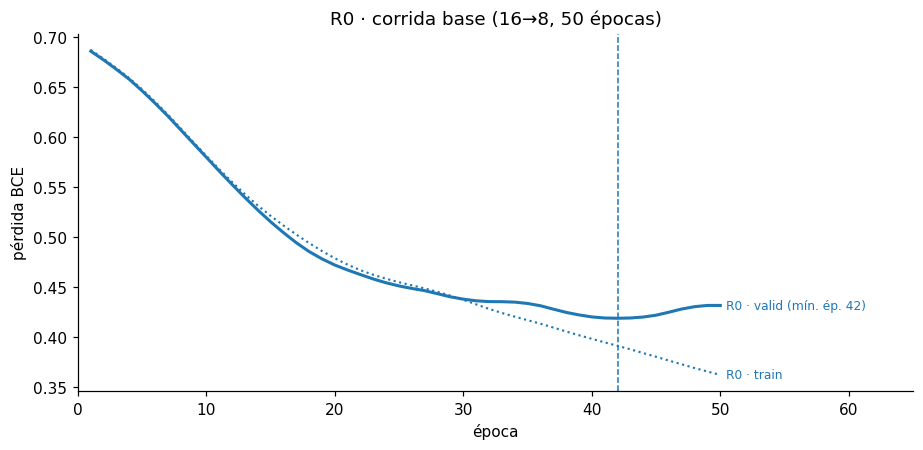

Pérdida train 0.688 → 0.362 | VALIDACIÓN (umbral 0,5): AUC 0.897, recall 0.741, FN 29, FP 17


In [ ]:
DIR_CKPT = Path("/content/drive/MyDrive/centinela_fase1") if (EN_COLAB and Path("/content/drive/MyDrive").exists()) else ROOT / "checkpoints"
DIR_CKPT.mkdir(parents=True, exist_ok=True)

def entrenar(nombre, Xtr, ytr, Xva, yva, ocultas=(16, 8), p_dropout=0.0, epocas=50, lr=1e-2,
             weight_decay=0.0, paciencia=None):
    fijar_semillas()
    modelo = MLP(Xtr.shape[1], ocultas, p_dropout)
    criterio = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train": [], "val": []}
    mejor = {"perdida": math.inf, "epoca": 0, "estado": copy.deepcopy(modelo.state_dict())}
    sin_mejora = 0
    for epoca in range(1, epocas + 1):
        modelo.train()
        logits = modelo(Xtr)                  # 1. forward
        perdida = criterio(logits, ytr)       # 2. pérdida
        optim.zero_grad()                     # 3. limpiar gradientes
        perdida.backward()                    # 4. retropropagación
        optim.step()                          # 5. actualizar pesos

        modelo.eval()
        with torch.no_grad():
            hist["train"].append(criterio(modelo(Xtr), ytr).item())
            hist["val"].append(criterio(modelo(Xva), yva).item())
        if hist["val"][-1] < mejor["perdida"] - 1e-4:
            mejor = {"perdida": hist["val"][-1], "epoca": epoca, "estado": copy.deepcopy(modelo.state_dict())}
            sin_mejora = 0
        else:
            sin_mejora += 1
        if epoca % 10 == 0:
            torch.save({"epoca": epoca, "modelo": modelo.state_dict(), "optim": optim.state_dict(),
                        "mejor_estado": mejor["estado"]}, DIR_CKPT / f"centinela_fase1_{nombre}.pt")
        if paciencia is not None and sin_mejora >= paciencia:
            break
    if paciencia is not None:
        modelo.load_state_dict(mejor["estado"])
    modelo.eval()
    return modelo, hist, mejor

def probabilidades(modelo, X):
    with torch.no_grad():
        return torch.sigmoid(modelo(X)).numpy().ravel()

def metricas(y, p, umbral=0.5):
    pred = (p >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    return {"umbral": umbral, "exactitud": accuracy_score(y, pred), "auc": roc_auc_score(y, p),
            "precision_afectada": pr[1], "recall_afectada": rc[1], "f1_afectada": f1[1],
            "precision_sana": pr[0], "recall_sana": rc[0], "f1_sana": f1[0],
            "VP": int(vp), "FN": int(fn), "FP": int(fp), "VN": int(vn), "costo": int(COSTO_FN * fn + COSTO_FP * fp)}

def graficar(corridas, titulo, archivo):
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    for i, (nom, (hist, mejor)) in enumerate(corridas.items()):
        c = plt.cm.tab10.colors[i]; ep = np.arange(1, len(hist["train"]) + 1)
        ax.plot(ep, hist["train"], color=c, ls=":", lw=1.4)
        ax.plot(ep, hist["val"], color=c, lw=2)
        ax.axvline(mejor["epoca"], color=c, ls="--", lw=1)
        ax.annotate(f"{nom} · train", (ep[-1], hist["train"][-1]), color=c, fontsize=8, xytext=(4, 0), textcoords="offset points", va="center")
        ax.annotate(f"{nom} · valid (mín. ép. {mejor['epoca']})", (ep[-1], hist["val"][-1]), color=c, fontsize=8, xytext=(4, 0), textcoords="offset points", va="center")
    ax.set_xlim(0, 1.3 * max(len(h["train"]) for h, _ in corridas.values()))
    ax.set_xlabel("época"); ax.set_ylabel("pérdida BCE"); ax.set_title(titulo)
    fig.tight_layout(); fig.savefig(FIG / archivo, bbox_inches="tight"); plt.show()

m_r0, h_r0, b_r0 = entrenar("R0_base", X_tr, y_tr, X_va, y_va)
graficar({"R0": (h_r0, b_r0)}, "R0 · corrida base (16→8, 50 épocas)", "curva_R0_base.png")
m_base_va = metricas(y_va_np, probabilidades(m_r0, X_va))
RESULTADOS["R0_validacion"] = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_base_va.items()}
print(f"Pérdida train {h_r0['train'][0]:.3f} → {h_r0['train'][-1]:.3f} | VALIDACIÓN (umbral 0,5): "
      f"AUC {m_base_va['auc']:.3f}, recall {m_base_va['recall_afectada']:.3f}, FN {m_base_va['FN']}, FP {m_base_va['FP']}")

**Lectura de R0.**
- La pérdida baja, así que el bucle aprende.
- En validación, con umbral 0,5, el *recall* de la clase afectada es **0,74**: lejos de la meta de 0,90.
- Por eso el umbral se elegirá según el costo del error, no se dejará en 0,5.

## 10 · Sobreajuste inducido (R1) y regularización
**R1: sobreajuste a propósito.** Red de 256 → 128, sin Dropout, sin parada temprana y 1.500 épocas.

Mínimo de validación en la época 30 (0.369); brecha valid − train: 0.135 en el mínimo, 1.99 al final


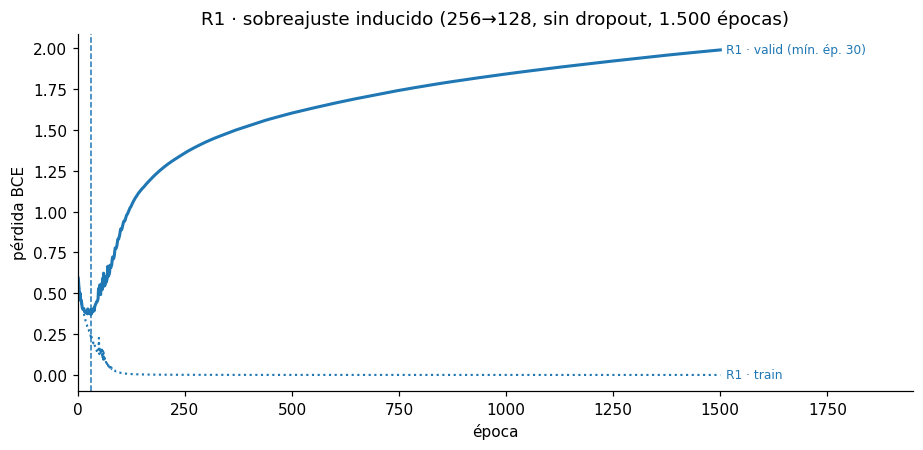

In [ ]:
m_r1, h_r1, b_r1 = entrenar("R1_sobreajuste", X_tr, y_tr, X_va, y_va, ocultas=(256, 128), epocas=1500)
print(f"Mínimo de validación en la época {b_r1['epoca']} ({b_r1['perdida']:.3f}); "
      f"brecha valid − train: {h_r1['val'][b_r1['epoca'] - 1] - h_r1['train'][b_r1['epoca'] - 1]:.3f} en el mínimo, "
      f"{h_r1['val'][-1] - h_r1['train'][-1]:.2f} al final")
graficar({"R1": (h_r1, b_r1)}, "R1 · sobreajuste inducido (256→128, sin dropout, 1.500 épocas)", "curva_R1_sobreajuste.png")

**Lectura de R1.**
- La validación toca su mínimo en la **época 30** y después sube sin parar, mientras el entrenamiento sigue bajando.
- La brecha pasa de **0,135** a **1,99**.
- Conclusión: hay sobreajuste; la red memoriza el entrenamiento.

**Corridas regularizadas.** Todas usan la misma semilla, la misma partición y la misma tasa de aprendizaje:

| Corrida | Qué cambia |
|---|---|
| R1-ES | La red de R1, solo con parada temprana |
| R2 | 16 → 8 con Dropout 0,3 |
| R3a / R3b | Comparación de tamaño: 8 → 4 frente a 64 → 32 |
| R4 | R2 + penalización L2 |

**Paciencia de 25 épocas.** El curso sugiere entre 5 y 10, pero con lote completo **1 época = 1 paso de gradiente**: 10 épocas detienen el entrenamiento en mesetas cortas (ver la auditoría del paso 13).

In [ ]:
PACIENCIA = 25
config = {
    "R1-ES": dict(ocultas=(256, 128), p_dropout=0.0, epocas=1500, paciencia=PACIENCIA),
    "R2":    dict(ocultas=(16, 8),    p_dropout=0.3, epocas=1500, paciencia=PACIENCIA),
    "R3a":   dict(ocultas=(8, 4),     p_dropout=0.3, epocas=1500, paciencia=PACIENCIA),
    "R3b":   dict(ocultas=(64, 32),   p_dropout=0.3, epocas=1500, paciencia=PACIENCIA),
    "R4":    dict(ocultas=(16, 8),    p_dropout=0.3, epocas=1500, paciencia=PACIENCIA, weight_decay=1e-3),
}
corridas = {"R0": (m_r0, h_r0, b_r0), "R1": (m_r1, h_r1, b_r1)}
for nom, cfg in config.items():
    corridas[nom] = entrenar(nom, X_tr, y_tr, X_va, y_va, **cfg)

info = {"R0": dict(ocultas=(16, 8), p_dropout=0.0), "R1": dict(ocultas=(256, 128), p_dropout=0.0), **config}
filas = []
for nom, (mod, hist, b) in corridas.items():
    e = b["epoca"]
    filas.append({"corrida": nom, "ocultas": str(info[nom]["ocultas"]), "dropout": info[nom].get("p_dropout", 0.0),
                  "weight_decay": info[nom].get("weight_decay", 0.0), "parada_temprana": nom in config,
                  "epocas_ejecutadas": len(hist["val"]), "epoca_min_val": e, "perdida_min_val": hist["val"][e - 1],
                  "perdida_train_en_min": hist["train"][e - 1], "brecha_en_min": hist["val"][e - 1] - hist["train"][e - 1],
                  "brecha_final": hist["val"][-1] - hist["train"][-1],
                  "auc_val_modelo_usado": roc_auc_score(y_va_np, probabilidades(mod, X_va))})
tabla_corridas = pd.DataFrame(filas).set_index("corrida")
tabla_corridas.to_csv(RES / "tabla_corridas.csv")

FINAL = tabla_corridas[tabla_corridas["parada_temprana"]]["perdida_min_val"].idxmin()   # se elige solo con validación
modelo_final = corridas[FINAL][0]
torch.save({"corrida": FINAL, "modelo": modelo_final.state_dict(), "rasgos": RASGOS}, DIR_CKPT / "centinela_fase1_final.pt")
RESULTADOS["corridas"] = tabla_corridas.round(4).reset_index().to_dict(orient="records")
RESULTADOS["modelo_final"] = FINAL
print("Modelo final:", FINAL)
tabla_corridas.round(4)

Modelo final: R3a


,ocultas,dropout,weight_decay,parada_temprana,epocas_ejecutadas,epoca_min_val,perdida_min_val,perdida_train_en_min,brecha_en_min,brecha_final,auc_val_modelo_usado
corrida,,,,,,,,,,,
R0,"(16, 8)",0.0,0.000,False,50,42,0.4185,0.3908,0.0276,0.0697,0.8967
R1,"(256, 128)",0.0,0.000,False,1500,30,0.3695,0.2343,0.1352,1.9892,0.9113
R1-ES,"(256, 128)",0.0,0.000,True,55,30,0.3695,0.2343,0.1352,0.4099,0.9413
R2,"(16, 8)",0.3,0.000,True,153,128,0.3607,0.3052,0.0555,0.0842,0.9419
R3a,"(8, 4)",0.3,0.000,True,190,165,0.3239,0.3222,0.0018,0.0222,0.9427
R3b,"(64, 32)",0.3,0.000,True,122,97,0.3271,0.2165,0.1106,0.1494,0.9482
R4,"(16, 8)",0.3,0.001,True,148,123,0.3586,0.3125,0.0462,0.0771,0.9429


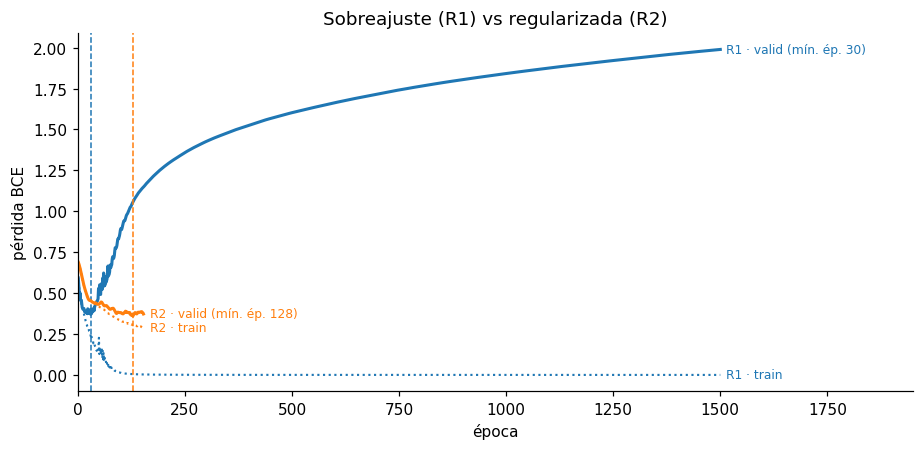

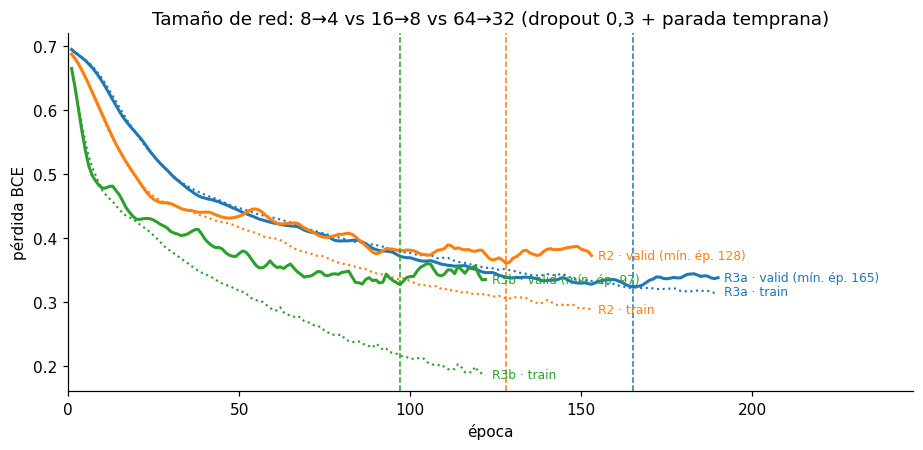

In [ ]:
graficar({"R1": corridas["R1"][1:], "R2": corridas["R2"][1:]}, "Sobreajuste (R1) vs regularizada (R2)", "curvas_R1_vs_R2.png")
graficar({k: corridas[k][1:] for k in ["R3a", "R2", "R3b"]}, "Tamaño de red: 8→4 vs 16→8 vs 64→32 (dropout 0,3 + parada temprana)", "curvas_capacidad.png")

**Lectura de las corridas** (pérdida mínima de validación · brecha en el mínimo):

| Corrida | Pérdida mín. | Brecha | Lectura |
|---|---|---|---|
| R1-ES | 0,370 | 0,135 | La parada temprana sola corta a tiempo, pero la brecha sigue alta |
| R2 | 0,361 | 0,056 | El Dropout baja la pérdida y reduce la brecha a menos de la mitad |
| R4 | 0,359 | 0,046 | Sumar L2 aporta poco |
| **R3a** | **0,324** | **0,002** | La red más pequeña generaliza mejor: menor pérdida y casi sin brecha |
| R3b | 0,327 | 0,111 | La red grande no gana pérdida y multiplica la brecha |

**Modelo final: R3a** (8 → 4, Dropout 0,3, parada temprana). Se eligió solo con validación y sigue teniendo dos capas ocultas.

## 11 · Evaluación
### 11.1 Umbral elegido en VALIDACIÓN según el costo
- Se prueban umbrales de 0,01 a 0,99.
- Se elige el que da **menor `5·FN + FP`** entre los que cumplen *recall* de la clase afectada ≥ 0,90.
- La misma regla se aplica al **escalar crudo** `pct_lesion`, que es una de las dos líneas base.

Umbral del MLP: 0.22 | umbral del escalar crudo: 0.0045


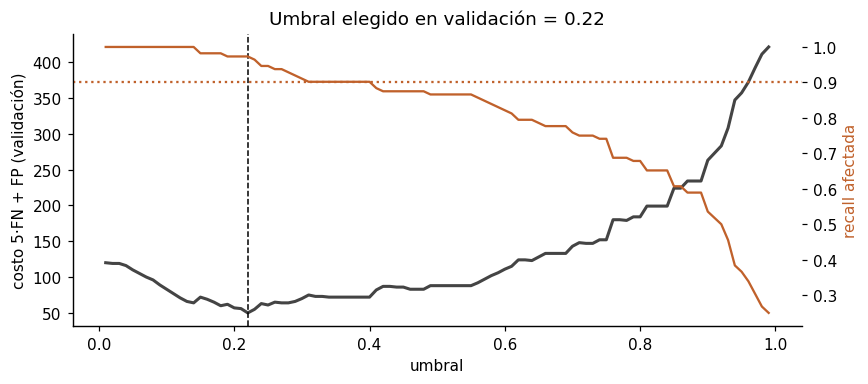

In [ ]:
def elegir_umbral(y, puntaje, rejilla):
    t = pd.DataFrame([metricas(y, puntaje, u) for u in rejilla])
    candidatos = t[t["recall_afectada"] >= RECALL_MIN]
    if candidatos.empty:
        candidatos = t
    return float(candidatos.sort_values(["costo", "umbral"], ascending=[True, False]).iloc[0]["umbral"]), t

REJILLA = np.round(np.arange(0.01, 1.00, 0.01), 2)
p_va = probabilidades(modelo_final, X_va)
UMBRAL, curva = elegir_umbral(y_va_np, p_va, REJILLA)
lesion_tr, lesion_va, lesion_te = (df.loc[s, "pct_lesion"].values for s in (es_tr, es_va, es_te))
UMBRAL_ESC, _ = elegir_umbral(y_va_np, lesion_va, np.unique(np.quantile(lesion_tr, np.linspace(0.01, 0.99, 99))))
print(f"Umbral del MLP: {UMBRAL:.2f} | umbral del escalar crudo: {UMBRAL_ESC:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curva["umbral"], curva["costo"], color="#444", lw=2); ax.axvline(UMBRAL, color="k", ls="--", lw=1)
ax2 = ax.twinx(); ax2.plot(curva["umbral"], curva["recall_afectada"], color="#c0612b"); ax2.axhline(RECALL_MIN, color="#c0612b", ls=":")
ax.set_xlabel("umbral"); ax.set_ylabel("costo 5·FN + FP (validación)"); ax2.set_ylabel("recall afectada", color="#c0612b")
ax.set_title(f"Umbral elegido en validación = {UMBRAL:.2f}")
fig.tight_layout(); fig.savefig(FIG / "umbral_validacion.png", bbox_inches="tight"); plt.show()

### 11.2 Prueba (una sola vez)
Esta es la **única** celda que usa el conjunto de prueba.

In [ ]:
p_te = probabilidades(modelo_final, X_te)
m_mlp = metricas(y_te_np, p_te, UMBRAL)
m_esc = metricas(y_te_np, lesion_te, UMBRAL_ESC)
mayoritaria = int(pd.Series(y_tr.numpy().ravel()).mode()[0])            # clase más frecuente en ENTRENAMIENTO
m_may = metricas(y_te_np, np.full(len(y_te_np), float(mayoritaria)))
m_may["auc"] = 0.5

comparacion = pd.DataFrame({f"MLP {FINAL}": m_mlp, "Escalar crudo pct_lesion": m_esc, "Clase mayoritaria (sana)": m_may}).T
comparacion.to_csv(RES / "metricas_prueba.csv")
RESULTADOS["prueba"] = {"umbral": UMBRAL, "umbral_escalar": UMBRAL_ESC, "n": int(len(y_te_np)),
                        "mlp": {k: round(float(v), 4) for k, v in m_mlp.items()},
                        "escalar": {k: round(float(v), 4) for k, v in m_esc.items()},
                        "mayoritaria": {k: round(float(v), 4) for k, v in m_may.items()}}
comparacion[["recall_afectada", "precision_afectada", "f1_afectada", "recall_sana", "precision_sana",
             "exactitud", "auc", "FN", "FP", "costo"]].astype(float).round(3)

,recall_afectada,precision_afectada,f1_afectada,recall_sana,precision_sana,exactitud,auc,FN,FP,costo
MLP R3a,0.975,0.748,0.847,0.667,0.963,0.822,0.936,3.0,39.0,54.0
Escalar crudo pct_lesion,0.992,0.578,0.731,0.265,0.969,0.631,0.789,1.0,86.0,91.0
Clase mayoritaria (sana),0.000,0.000,0.000,1.000,0.496,0.496,0.500,119.0,0.0,595.0


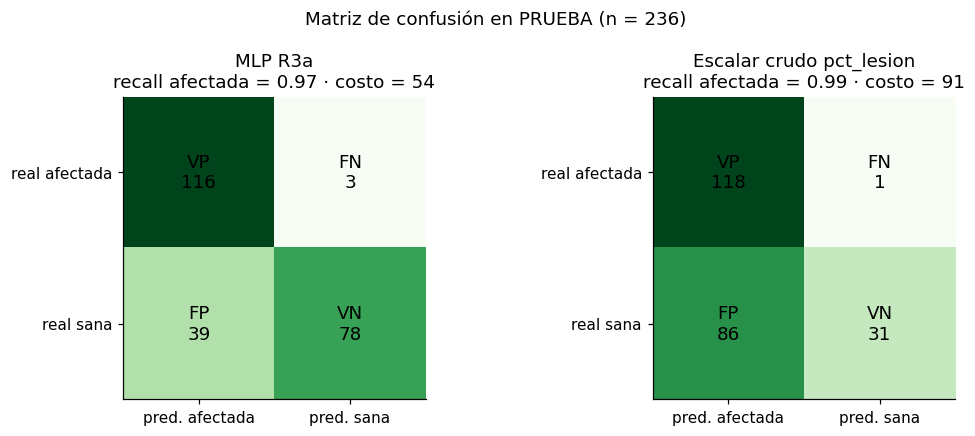

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (titulo, m) in zip(axes, [(f"MLP {FINAL}", m_mlp), ("Escalar crudo pct_lesion", m_esc)]):
    matriz = np.array([[m["VP"], m["FN"]], [m["FP"], m["VN"]]])
    ax.imshow(matriz, cmap="Greens")
    for (i, j), v in np.ndenumerate(matriz):
        ax.text(j, i, f"{['VP', 'FN', 'FP', 'VN'][2 * i + j]}\n{v}", ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1], ["pred. afectada", "pred. sana"]); ax.set_yticks([0, 1], ["real afectada", "real sana"])
    ax.set_title(f"{titulo}\nrecall afectada = {m['recall_afectada']:.2f} · costo = {m['costo']}")
fig.suptitle(f"Matriz de confusión en PRUEBA (n = {len(y_te_np)})")
fig.tight_layout(); fig.savefig(FIG / "matriz_confusion_prueba.png", bbox_inches="tight"); plt.show()

**Lectura** (n = 236; umbral 0,22):

| Modelo | *Recall* afectada | Precisión afectada | F1 | AUC | Costo |
|---|---|---|---|---|---|
| **MLP R3a** | **0,975** | 0,748 | **0,847** | **0,936** | **54** |
| Escalar crudo | 0,992 | 0,578 | 0,731 | 0,789 | 91 |
| Clase mayoritaria | 0 | — | 0 | 0,5 | 595 |

- El MLP detecta 116 de 119 hojas afectadas y cumple la meta.
- Frente a mirar un solo número (`pct_lesion`), reduce el costo un 41 % y las falsas alarmas de 86 a 39.
- El precio de priorizar el *recall*: 1 de cada 3 hojas sanas genera una alerta que el técnico descarta en campo.

### 11.3 Errores por subgrupo

In [ ]:
te = df.loc[es_te, ["archivo", "clase", "cara", "dispositivo", "fecha_txt", "afectada"]].copy()
te["p"], te["pred"] = p_te, (p_te >= UMBRAL).astype(int)
por_clase = te.groupby("clase").agg(n=("archivo", "size"), tasa_alerta=("pred", "mean")).reindex(ORDEN)
def por(v):
    return te.groupby(v).apply(lambda g: pd.Series({
        "n": len(g), "n_afectadas": int(g["afectada"].sum()),
        "recall_afectada": g.loc[g["afectada"] == 1, "pred"].mean(),
        "tasa_FP_sanas": g.loc[g["afectada"] == 0, "pred"].mean()}), include_groups=False)
sub_cara, sub_disp, sub_fecha = por("cara"), por("dispositivo"), por("fecha_txt")
RESULTADOS["subgrupos"] = {"por_clase": por_clase["tasa_alerta"].round(3).to_dict(), "por_clase_n": por_clase["n"].to_dict(),
                           "por_cara": sub_cara.round(3).to_dict(orient="index"),
                           "por_dispositivo": sub_disp.round(3).to_dict(orient="index"),
                           "por_fecha": sub_fecha.round(3).to_dict(orient="index")}
print("Tasa de alerta por clase (en 'sana' es la tasa de falsa alarma):"); print(por_clase.round(3))
print("\nPor celular:"); print(sub_disp.round(3))

Tasa de alerta por clase (en 'sana' es la tasa de falsa alarma):
              n  tasa_alerta
clase                       
sana        117        0.333
ácaro rojo   28        0.964
roya 1       55        0.964
roya 2       26        1.000
roya 3        6        1.000
roya 4        4        1.000

Por celular:
                     n  n_afectadas  recall_afectada  tasa_FP_sanas
dispositivo                                                        
samsung SM-G610M  44.0         24.0            0.958          0.100
samsung SM-J200M  83.0         42.0            1.000          0.537
samsung SM-J320H  24.0         12.0            1.000          0.167
samsung SM-J700M  85.0         41.0            0.951          0.295


**Lectura.**
- **Severidad:** se escapan sobre todo las lesiones **incipientes** (roya 1 y ácaro, con 0,964 de detección). Las de roya 2–4 se detectan todas, aunque hay pocas roya 3 y 4 en prueba.
- **Celular:** el *recall* es estable, pero la falsa alarma en hojas sanas **depende de la cámara**: de 0,10 (SM-G610M) a 0,54 (SM-J200M).
- **Política:** vigilar la falsa alarma por celular. En la Fase 2, normalizar el color.

## 12 · Interpretación
### 12.1 ¿Qué rasgos usa el modelo? (importancia por permutación, en validación)
Se desordenan los valores de un rasgo y se mide cuánto cae la AUC. Si cae mucho, el modelo depende de ese rasgo.

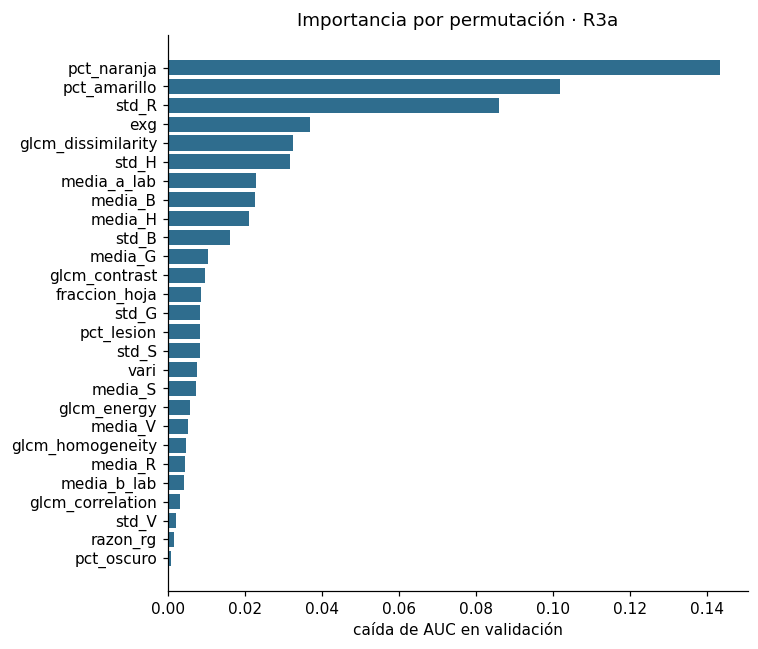

In [ ]:
rng = np.random.default_rng(SEMILLA)
auc_ref = roc_auc_score(y_va_np, p_va)
importancia = {}
for j, c in enumerate(RASGOS):
    caidas = []
    for _ in range(20):
        Xp = X_va.clone(); Xp[:, j] = Xp[rng.permutation(len(Xp)), j]
        caidas.append(auc_ref - roc_auc_score(y_va_np, probabilidades(modelo_final, Xp)))
    importancia[c] = np.mean(caidas)
importancia = pd.Series(importancia).sort_values()
RESULTADOS["importancia_top5"] = importancia.sort_values(ascending=False).head(5).round(4).to_dict()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(importancia.index, importancia.values, color=np.where(importancia.values > 0, "#2f6d8e", "#bbbbbb"))
ax.set_xlabel("caída de AUC en validación"); ax.set_title(f"Importancia por permutación · {FINAL}")
fig.tight_layout(); fig.savefig(FIG / "importancia_permutacion.png", bbox_inches="tight"); plt.show()

**Lectura.** El modelo se apoya sobre todo en el **color de la lesión**: `pct_naranja`, `pct_amarillo` y la variación del canal rojo. Es coherente con la biología: pústulas anaranjadas, clorosis y bronceado.

También explica las falsas alarmas: brillos y tonos amarillentos en hojas sanas "parecen" lesión.

### 12.2 Galería de errores en prueba

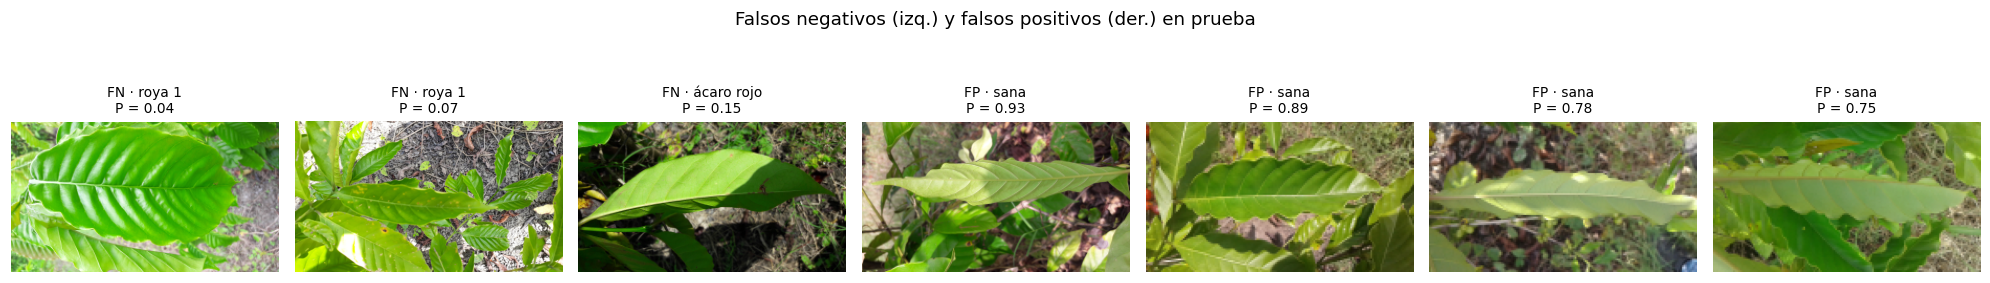

In [ ]:
errores = pd.concat([te[(te["afectada"] == 1) & (te["pred"] == 0)].sort_values("p").head(4).assign(tipo="FN"),
                     te[(te["afectada"] == 0) & (te["pred"] == 1)].sort_values("p", ascending=False).head(4).assign(tipo="FP")])
fig, axes = plt.subplots(1, len(errores), figsize=(2.6 * len(errores), 3.2))
for ax, (_, fila) in zip(np.atleast_1d(axes), errores.iterrows()):
    im = Image.open(RAW / "Photos" / fila["archivo"]); im.draft("RGB", (im.width // 8, im.height // 8))
    ax.imshow(im.convert("RGB")); ax.axis("off"); ax.set_title(f"{fila['tipo']} · {fila['clase']}\nP = {fila['p']:.2f}", fontsize=9)
fig.suptitle("Falsos negativos (izq.) y falsos positivos (der.) en prueba")
fig.tight_layout(); fig.savefig(FIG / "galeria_errores.png", bbox_inches="tight"); plt.show()

### 12.3 Reflexión ética: Marco Ético para la IA en Colombia (2021)
- **Responsabilidad.** El umbral (0,22) se fijó por el costo del error para el cliente. La salida es una **alerta de inspección**, no un diagnóstico: el técnico confirma en campo antes de aplicar cualquier producto.
- **Transparencia.** Se declara el dominio de validez: robusta, un solo sitio (CIIDEA, Manabí), 5 días de 2019 y 4 celulares. "Sin alerta" no significa "sana". Se reporta la falsa alarma por celular.
- **Equidad y beneficio social.** No se debe extrapolar a café arábica ni a fincas colombianas sin un piloto local. Hacerlo trasladaría el riesgo de los FN a productores que el modelo no vio.
- **Datos.** No hay personas identificables ni GPS. El dato del anotador (`Created By`) se eliminó al cargar.

## 13 · Auditoría a la IA
### 13.1 Caso real: paciencia de la parada temprana
- **Qué pasó.** El asistente de IA generó el bucle con `PACIENCIA = 10`, el rango que sugiere el curso.
- **Por qué estaba mal.** Con lote completo, 10 épocas son solo 10 pasos de gradiente. En la primera ejecución, R2 y R4 se detenían en la época 57.
- **Cómo se reproduce.** Misma configuración (R2) y misma semilla, con paciencia 10 frente a 25. Se mide en validación.

In [ ]:
filas = []
for pac in (10, 25):
    cfg = dict(config["R2"], paciencia=pac)
    mod, hist, b = entrenar(f"auditoria_paciencia_{pac}", X_tr, y_tr, X_va, y_va, **cfg)
    p = probabilidades(mod, X_va)
    u, _ = elegir_umbral(y_va_np, p, REJILLA)
    m = metricas(y_va_np, p, u)
    filas.append({"paciencia": pac, "epoca_detencion": len(hist["val"]), "epoca_min_val": b["epoca"], "perdida_min_val": b["perdida"],
                  "auc_val": m["auc"], "umbral_val": u, "recall_val": m["recall_afectada"],
                  "precision_val": m["precision_afectada"], "costo_val": m["costo"]})
auditoria_paciencia = pd.DataFrame(filas).set_index("paciencia")
RESULTADOS["auditoria_paciencia"] = auditoria_paciencia.round(4).reset_index().to_dict(orient="records")
auditoria_paciencia.round(3)

,epoca_detencion,epoca_min_val,perdida_min_val,auc_val,umbral_val,recall_val,precision_val,costo_val
paciencia,,,,,,,,
10,57,47,0.431,0.893,0.26,0.964,0.647,79
25,153,128,0.361,0.942,0.20,0.973,0.741,53


**Resultado.**
- Con paciencia 10 el entrenamiento se detiene en la época 57: AUC de validación **0,893** y costo **79**.
- Con paciencia 25 llega a la época 153: AUC **0,942** y costo **53**.
- **Lección:** un hiperparámetro "recomendado" se traduce a la unidad real del algoritmo, que son los pasos de gradiente, no las épocas.

### 13.2 Caso inducido: partir por foto en lugar de por planta
- **Qué se reproduce.** La partición "estándar" que suele proponer un asistente: `train_test_split` por foto.
- **Por qué está mal.** Ignora que hay 4 fotos por planta y que hay duplicados.

In [ ]:
idx = np.arange(len(df))
idx_resto, idx_te_ing = train_test_split(idx, test_size=0.15, stratify=df["afectada"], random_state=SEMILLA)
idx_tr_ing, idx_va_ing = train_test_split(idx_resto, test_size=0.15 / 0.85, stratify=df["afectada"].iloc[idx_resto], random_state=SEMILLA)
fuga_grupo = df["id_grupo"].iloc[idx_te_ing].isin(set(df["id_grupo"].iloc[idx_tr_ing])).mean()
fuga_copias = int(df["sha256"].iloc[idx_te_ing].isin(set(df["sha256"].iloc[idx_tr_ing])).sum())

filas_df = lambda ii: df.index[ii]
esc_ing = StandardScaler().fit(df.loc[filas_df(idx_tr_ing), RASGOS])
Xtr_i, ytr_i = a_tensores(filas_df(idx_tr_ing), esc_ing)
Xva_i, yva_i = a_tensores(filas_df(idx_va_ing), esc_ing)
Xte_i, yte_i = a_tensores(filas_df(idx_te_ing), esc_ing)
mod_ing, _, _ = entrenar("auditoria_particion_ingenua", Xtr_i, ytr_i, Xva_i, yva_i, **config[FINAL])
u_ing, _ = elegir_umbral(yva_i.numpy().ravel().astype(int), probabilidades(mod_ing, Xva_i), REJILLA)
m_ing = metricas(yte_i.numpy().ravel().astype(int), probabilidades(mod_ing, Xte_i), u_ing)

RESULTADOS["auditoria"] = {"pct_prueba_con_grupo_en_train_ingenua": round(float(fuga_grupo), 3),
                           "duplicados_exactos_prueba_en_train_ingenua": fuga_copias,
                           "ingenua": {k: round(float(v), 4) for k, v in m_ing.items()},
                           "corregida": {k: round(float(v), 4) for k, v in m_mlp.items()}}
print(f"Partición por foto: {fuga_grupo:.1%} de las fotos de prueba tienen una hermana en entrenamiento; {fuga_copias} son copias exactas.")
pd.DataFrame({"Por foto (IA)": m_ing, "Por planta (corregida)": m_mlp}).T[["auc", "recall_afectada", "f1_afectada", "costo"]].astype(float).round(3)

Partición por foto: 99.1% de las fotos de prueba tienen una hermana en entrenamiento; 20 son copias exactas.


,auc,recall_afectada,f1_afectada,costo
Por foto (IA),0.914,0.948,0.796,80.0
Por planta (corregida),0.936,0.975,0.847,54.0


**Resultado.**
- En la partición por foto, el 99,1 % de las fotos de prueba tiene una hermana en entrenamiento, y 20 son copias exactas.
- En esta semilla la métrica **no se infló**: AUC 0,914 con la partición por foto frente a 0,936 con la partición por planta.
- **Lección:** la fuga no siempre se ve en el número. Se controla por construcción, con los `assert` del paso 6.

## 14 · Conclusiones
1. **Problema → modelo.** Un MLP pequeño (8 → 4) sobre 27 rasgos de color y textura separa hojas afectadas de sanas con AUC = 0,936 en prueba. Supera la clase mayoritaria y el escalar crudo.
2. **Error → decisión.** Con el costo 5:1 y un umbral de 0,22, detecta el 97,5 % de las hojas afectadas (3 FN) a cambio de 39 falsas alarmas.
3. **Recomendación.** Usarlo como **filtro para priorizar la inspección**, no como diagnóstico. Toda alerta se confirma en campo y la falsa alarma se vigila por celular.
4. **Limitaciones:**
   - Un sitio y solo robusta.
   - 5 días de captura, con clima casi constante.
   - Ruido de etiqueta en duplicados.
   - Recorte de la hoja con la anotación humana.
5. **Fase 2.** Se conservan la partición, la semilla, el umbral y las líneas base. La CNN reemplazará los rasgos hechos a mano y la LSTM/GRU agregará los 60 días de clima.

La celda final exporta `resultados/resultados.json`, de donde salen las cifras del informe.

In [ ]:
RESULTADOS["clima_ventanas_60d"] = ventanas.assign(fecha=ventanas["fecha"].astype(str)).round(3).to_dict(orient="records")
with open(RES / "resultados.json", "w", encoding="utf-8") as fh:
    json.dump(RESULTADOS, fh, ensure_ascii=False, indent=2,
              default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("resultados.json exportado | modelo", FINAL, "| umbral", UMBRAL, "| costo en prueba", m_mlp["costo"])

resultados.json exportado | modelo R3a | umbral 0.22 | costo en prueba 54
